Section	Purpose
1. Setup	Import libraries and define paths
2. Data preparation	Load the existing data and prepare splits
3. Classification	Train a basic crack/no-crack model
4. YOLO detection	Train a model to locate cracks
5. U-Net segmentation	Train a model to identify crack pixels
6. Evaluation	Calculate metrics and visualize results
7. Summary	Record what worked and what remains

In [ ]:
# Section 1: Setup

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Project directories
PROJECT_DIR = Path("/content/InfraScan")
DATASET_DIR = PROJECT_DIR / "datasets"
MANIFEST_DIR = PROJECT_DIR / "manifests"
PROCESSED_DIR = PROJECT_DIR / "processed"

print("Project directory exists:", PROJECT_DIR.exists())
print("Dataset directory exists:", DATASET_DIR.exists())
print("Manifest directory exists:", MANIFEST_DIR.exists())
print("Processed directory exists:", PROCESSED_DIR.exists())

Project directory exists: False
Dataset directory exists: False
Manifest directory exists: False
Processed directory exists: False


In [ ]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
from pathlib import Path

DRIVE_DIR = Path("/content/drive/MyDrive")

print("My Drive exists:", DRIVE_DIR.exists())
print("\nFolders in My Drive:")

for folder in sorted(DRIVE_DIR.iterdir()):
    if folder.is_dir():
        print(folder.name)

My Drive exists: True

Folders in My Drive:
Classroom
Colab Notebooks
InfraScan
Science


In [ ]:
from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/InfraScan")

print("InfraScan exists:", PROJECT_DIR.exists())
print("\nContents of InfraScan:")

for item in sorted(PROJECT_DIR.iterdir()):
    print(f"{'[Folder]' if item.is_dir() else '[File]'} {item.name}")

InfraScan exists: True

Contents of InfraScan:
[Folder] datasets
[Folder] eda_results
[Folder] manifests
[Folder] processed


In [ ]:
DATASET_DIR = PROJECT_DIR / "datasets"

print("Contents of datasets:")

for item in sorted(DATASET_DIR.iterdir()):
    print(f"{'[Folder]' if item.is_dir() else '[File]'} {item.name}")

Contents of datasets:
[File] 5y9wdsg2zt-2.zip
[File] Concrete Crack Images for Classification.rar
[Folder] Concrete_Crack_Classification
[File] CrackForest-dataset-master.zip
[File] DATA_Maguire_20180517_ALL.zip
[File] archive.zip


In [ ]:
from zipfile import ZipFile

for zip_path in sorted(DATASET_DIR.glob("*.zip")):
    print(f"\n{zip_path.name}")

    try:
        with ZipFile(zip_path) as z:
            print("  Valid ZIP:", z.testzip() is None)
            print("  Entries:", len(z.namelist()))
            print("  First 5 entries:")
            for name in z.namelist()[:5]:
                print("   ", name)
    except Exception as e:
        print("  Error:", e)


5y9wdsg2zt-2.zip
  Valid ZIP: True
  Entries: 1
  First 5 entries:
    Concrete Crack Images for Classification.rar

CrackForest-dataset-master.zip
  Valid ZIP: True
  Entries: 397
  First 5 entries:
    CrackForest-dataset-master/
    CrackForest-dataset-master/README.md
    CrackForest-dataset-master/groundTruth/
    CrackForest-dataset-master/groundTruth/001.mat
    CrackForest-dataset-master/groundTruth/002.mat

DATA_Maguire_20180517_ALL.zip
  Valid ZIP: True
  Entries: 2
  First 5 entries:
    DATA_Maguire_20180517_ALL/ReadMe_SDNET2018 .txt
    DATA_Maguire_20180517_ALL/SDNET2018.zip

archive.zip
  Valid ZIP: True
  Entries: 10487
  First 5 entries:
    CRACK500/fphb_testresult/hed_fuse_fpn_ada_python_v1_iter_12000/20160222_080933_361_1.mat
    CRACK500/fphb_testresult/hed_fuse_fpn_ada_python_v1_iter_12000/20160222_080933_361_1.png
    CRACK500/fphb_testresult/hed_fuse_fpn_ada_python_v1_iter_12000/20160222_080933_361_1281.mat
    CRACK500/fphb_testresult/hed_fuse_fpn_ada_python_v

In [ ]:
for path in PROJECT_DIR.rglob("*"):
    if path.is_dir():
        depth = len(path.relative_to(PROJECT_DIR).parts)
        if depth <= 3:
            print("[Folder]", path.relative_to(PROJECT_DIR))
    elif path.suffix.lower() in {".csv", ".json", ".npy", ".png", ".jpg", ".jpeg"}:
        print("[File]", path.relative_to(PROJECT_DIR))

Streaming output truncated to the last 5000 lines.
[File] datasets/Concrete_Crack_Classification/Positive/04001.jpg
[File] datasets/Concrete_Crack_Classification/Positive/04002.jpg
[File] datasets/Concrete_Crack_Classification/Positive/04003.jpg
[File] datasets/Concrete_Crack_Classification/Positive/04004.jpg
[File] datasets/Concrete_Crack_Classification/Positive/04005.jpg
[File] datasets/Concrete_Crack_Classification/Positive/04006.jpg
[File] datasets/Concrete_Crack_Classification/Positive/04007.jpg
[File] datasets/Concrete_Crack_Classification/Positive/04008.jpg
[File] datasets/Concrete_Crack_Classification/Positive/04009.jpg
[File] datasets/Concrete_Crack_Classification/Positive/04010.jpg
[File] datasets/Concrete_Crack_Classification/Positive/04011.jpg
[File] datasets/Concrete_Crack_Classification/Positive/04012.jpg
[File] datasets/Concrete_Crack_Classification/Positive/04013.jpg
[File] datasets/Concrete_Crack_Classification/Positive/04014.jpg
[File] datasets/Concrete_Crack_Classifi

In [ ]:
for zip_path in sorted(DATASET_DIR.glob("*.zip")):
    size_gb = zip_path.stat().st_size / (1024 ** 3)
    print(f"{zip_path.name}: {size_gb:.2f} GB")

5y9wdsg2zt-2.zip: 0.22 GB
CrackForest-dataset-master.zip: 0.01 GB
DATA_Maguire_20180517_ALL.zip: 0.49 GB
archive.zip: 1.53 GB


In [ ]:
import shutil

total, used, free = shutil.disk_usage("/content")

print(f"Total: {total / (1024**3):.2f} GB")
print(f"Used:  {used / (1024**3):.2f} GB")
print(f"Free:  {free / (1024**3):.2f} GB")

Total: 112.64 GB
Used:  2.39 GB
Free:  110.23 GB


In [ ]:
MANIFEST_DIR = PROJECT_DIR / "manifests"
PROCESSED_DIR = PROJECT_DIR / "processed"
EDA_DIR = PROJECT_DIR / "eda_results"

for folder in [MANIFEST_DIR, PROCESSED_DIR, EDA_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("Created project folders:")
print("Manifests:", MANIFEST_DIR)
print("Processed:", PROCESSED_DIR)
print("EDA results:", EDA_DIR)

Created project folders:
Manifests: /content/drive/MyDrive/InfraScan/manifests
Processed: /content/drive/MyDrive/InfraScan/processed
EDA results: /content/drive/MyDrive/InfraScan/eda_results


In [ ]:
print("Dataset archives:")

for zip_path in sorted(DATASET_DIR.glob("*.zip")):
    print(zip_path.name, "—", zip_path.exists())

Dataset archives:
5y9wdsg2zt-2.zip — True
CrackForest-dataset-master.zip — True
DATA_Maguire_20180517_ALL.zip — True
archive.zip — True


2. Data preparation	Load the existing data and prepare splits

In [ ]:
from zipfile import ZipFile

classification_zip = DATASET_DIR / "5y9wdsg2zt-2.zip"
classification_rar = DATASET_DIR / "Concrete Crack Images for Classification.rar"

with ZipFile(classification_zip, "r") as z:
    z.extract(
        "Concrete Crack Images for Classification.rar",
        path=DATASET_DIR
    )

print("RAR extracted:", classification_rar.exists())
print("RAR size:", f"{classification_rar.stat().st_size / (1024**3):.2f} GB")

RAR extracted: True
RAR size: 0.22 GB


In [ ]:
%pip install -q rarfile

import rarfile
print("rarfile installed:", rarfile.__version__)

rarfile installed: 4.5


In [ ]:
import rarfile

with rarfile.RarFile(classification_rar) as rar:
    print("Total entries:", len(rar.infolist()))
    print("\nFirst 15 entries:")

    for item in rar.infolist()[:15]:
        print(item.filename)

Total entries: 40002

First 15 entries:
Positive/00001.jpg
Positive/00002.jpg
Positive/00003.jpg
Positive/00004.jpg
Positive/00005.jpg
Positive/00006.jpg
Positive/00007.jpg
Positive/00008.jpg
Positive/00009.jpg
Positive/00010.jpg
Positive/00011.jpg
Positive/00012.jpg
Positive/00013.jpg
Positive/00014.jpg
Positive/00015.jpg


In [ ]:
import rarfile
from collections import Counter

with rarfile.RarFile(classification_rar) as rar:
    class_counts = Counter(
        item.filename.split("/")[0]
        for item in rar.infolist()
        if item.filename.lower().endswith((".jpg", ".jpeg", ".png"))
    )

print("Class counts:")
for class_name, count in sorted(class_counts.items()):
    print(f"{class_name}: {count}")

Class counts:
Negative: 20000
Positive: 20000


In [ ]:
#extract img
CLASSIFICATION_DIR = DATASET_DIR / "Concrete_Crack_Classification"

CLASSIFICATION_DIR.mkdir(parents=True, exist_ok=True)

with rarfile.RarFile(classification_rar) as rar:
    rar.extractall(CLASSIFICATION_DIR)

print("Extraction complete.")
print("Dataset directory:", CLASSIFICATION_DIR)
print("Positive folder exists:", (CLASSIFICATION_DIR / "Positive").exists())
print("Negative folder exists:", (CLASSIFICATION_DIR / "Negative").exists())

KeyboardInterrupt: 

In [ ]:
from pathlib import Path
import pandas as pd

image_extensions = {".jpg", ".jpeg", ".png"}

records = []

for label_name, label in [("Negative", 0), ("Positive", 1)]:
    folder = CLASSIFICATION_DIR / label_name

    for image_path in folder.iterdir():
        if image_path.suffix.lower() in image_extensions:
            records.append({
                "image_path": str(image_path),
                "label": label,
                "class_name": label_name
            })

classification_df = pd.DataFrame(records)

print("Total images:", len(classification_df))
print("\nClass distribution:")
print(classification_df["class_name"].value_counts())
print("\nFirst 5 rows:")
display(classification_df.head())

Total images: 23691

Class distribution:
class_name
Positive    20000
Negative     3691
Name: count, dtype: int64

First 5 rows:


,image_path,label,class_name
0,/content/drive/MyDrive/InfraScan/datasets/Conc...,0,Negative
1,/content/drive/MyDrive/InfraScan/datasets/Conc...,0,Negative
2,/content/drive/MyDrive/InfraScan/datasets/Conc...,0,Negative
3,/content/drive/MyDrive/InfraScan/datasets/Conc...,0,Negative
4,/content/drive/MyDrive/InfraScan/datasets/Conc...,0,Negative


In [ ]:
from pathlib import Path

for class_name in ["Negative", "Positive"]:
    folder = CLASSIFICATION_DIR / class_name

    print(f"\n{class_name} folder:")
    print("Exists:", folder.exists())

    if folder.exists():
        print("Direct files:", sum(p.is_file() for p in folder.iterdir()))
        print("Images recursively:", sum(
            1 for p in folder.rglob("*")
            if p.is_file() and p.suffix.lower() in image_extensions
        ))

        print("Sample entries:")
        for p in list(folder.iterdir())[:5]:
            print(" ", p.name)


Negative folder:
Exists: True
Direct files: 3691
Images recursively: 3691
Sample entries:
  02692.jpg
  02693.jpg
  02694.jpg
  02695.jpg
  02696.jpg

Positive folder:
Exists: True
Direct files: 20000
Images recursively: 20000
Sample entries:
  19001_1.jpg
  19002_1.jpg
  19003_1.jpg
  19004_1.jpg
  19005_1.jpg


In [ ]:

Negative folder:
Exists: True
Direct files: 3691
Images recursively: 3691
Sample entries:
  02692.jpg
  02693.jpg
  02694.jpg
  02695.jpg
  02696.jpg

Positive folder:
Exists: True
Direct files: 20000
Images recursively: 20000
Sample entries:
  19001_1.jpg
  19002_1.jpg
  19003_1.jpg
  19004_1.jpg
  19005_1.jpg

SyntaxError: invalid imaginary literal (3795645454.py, line 6)

In [ ]:
import zipfile
from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/InfraScan")
DATASET_DIR = PROJECT_DIR / "datasets"
PROCESSED_DIR = PROJECT_DIR / "processed"

archive_path = DATASET_DIR / "archive.zip"
YOLO_DIR = PROCESSED_DIR / "YOLO_CRACK500"
RAW_CROPS_DIR = YOLO_DIR / "raw_crops"

RAW_CROPS_DIR.mkdir(parents=True, exist_ok=True)

splits = ["traincrop", "valcrop", "testcrop"]

with zipfile.ZipFile(archive_path) as z:
    for split in splits:
        members = [
            name for name in z.namelist()
            if name.startswith(f"CRACK500/{split}/")
            and name.lower().endswith((".jpg", ".png"))
        ]

        print(f"Extracting {split}: {len(members)} files")
        for member in members:
            relative_path = Path(*member.split("/")[2:])
            output_path = RAW_CROPS_DIR / split / relative_path

            output_path.parent.mkdir(parents=True, exist_ok=True)

            if not output_path.exists():
                with z.open(member) as src, open(output_path, "wb") as dst:
                    dst.write(src.read())

print("\nExtraction complete.")
print("Saved to:", RAW_CROPS_DIR)

Extracting traincrop: 3792 files
Extracting valcrop: 696 files
Extracting testcrop: 2248 files

Extraction complete.
Saved to: /content/drive/MyDrive/InfraScan/processed/YOLO_CRACK500/raw_crops


In [ ]:
from pathlib import Path

RAW_CROPS_DIR = Path("/content/drive/MyDrive/InfraScan/processed/YOLO_CRACK500/raw_crops")

for split in ["traincrop", "valcrop", "testcrop"]:
    split_dir = RAW_CROPS_DIR / split

    images = list(split_dir.rglob("*.jpg"))
    masks = list(split_dir.rglob("*.png"))

    print(f"{split}: {len(images)} images, {len(masks)} masks")
    print("Example image:", images[0].name if images else "None")
    print("Example mask:", masks[0].name if masks else "None")

traincrop: 1896 images, 1896 masks
Example image: 20160222_081011_1281_721.jpg
Example mask: 20160222_081011_1281_721.png
valcrop: 348 images, 348 masks
Example image: 20160222_080850_1281_361.jpg
Example mask: 20160222_080850_1281_361.png
testcrop: 1124 images, 1124 masks
Example image: 20160222_080933_361_1.jpg
Example mask: 20160222_080933_361_1.png


In [ ]:
from sklearn.model_selection import train_test_split

# First, separate 15% for testing
train_val_df, test_df = train_test_split(
    classification_df,
    test_size=0.15,
    stratify=classification_df["label"],
    random_state=42
)

# Then separate 15% of the total data for validation
val_size = 0.15 / 0.85

train_df, val_df = train_test_split(
    train_val_df,
    test_size=val_size,
    stratify=train_val_df["label"],
    random_state=42
)

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

In [ ]:
# Save the complete manifest and each split
classification_df.to_csv(
    MANIFEST_DIR / "classification_manifest.csv",
    index=False
)

train_df.to_csv(MANIFEST_DIR / "classification_train.csv", index=False)
val_df.to_csv(MANIFEST_DIR / "classification_val.csv", index=False)
test_df.to_csv(MANIFEST_DIR / "classification_test.csv", index=False)

print("Saved files:")
for filename in [
    "classification_manifest.csv",
    "classification_train.csv",
    "classification_val.csv",
    "classification_test.csv"
]:
    print(filename, "—", (MANIFEST_DIR / filename).exists())

In [ ]:
from zipfile import ZipFile

crack500_zip = DATASET_DIR / "archive.zip"

with ZipFile(crack500_zip, "r") as z:
    names = z.namelist()

    print("Total archive entries:", len(names))
    print("\nTop-level folders:")

    top_folders = sorted({
        name.split("/")[1]
        for name in names
        if name.startswith("CRACK500/") and len(name.split("/")) > 2
    })

    for folder in top_folders:
        print(folder)# preparing the segmentation data. This uses images with pixel-level crack masks, which are required to train U-Net.

In [ ]:
from zipfile import ZipFile

with ZipFile(crack500_zip, "r") as z:
    for folder in ["traindata", "valdata", "testdata"]:
        print(f"\n{folder}:")
        entries = [
            name for name in z.namelist()
            if name.startswith(f"CRACK500/{folder}/")
        ]

        print("Entries:", len(entries))
        for name in entries[:10]:
            print(" ", name)

In [ ]:
from zipfile import ZipFile
from pathlib import PurePosixPath

with ZipFile(crack500_zip, "r") as z:
    for folder in ["traindata", "valdata", "testdata"]:
        paths = [
            name for name in z.namelist()
            if name.startswith(f"CRACK500/{folder}/")
        ]

        images = [
            name for name in paths
            if PurePosixPath(name).suffix.lower() in {".jpg", ".jpeg"}
        ]

        masks = [
            name for name in paths
            if name.endswith("_mask.png")
        ]

        print(f"{folder}:")
        print("  Images:", len(images))
        print("  Masks:", len(masks))

In [ ]:
from zipfile import ZipFile
from PIL import Image
from io import BytesIO
import matplotlib.pyplot as plt

with ZipFile(crack500_zip, "r") as z:
    image_path = "CRACK500/traindata/traindata/20160222_081011.jpg"
    mask_path = "CRACK500/traindata/traindata/20160222_081011_mask.png"

    image = Image.open(BytesIO(z.read(image_path))).convert("RGB")
    mask = Image.open(BytesIO(z.read(mask_path)))

print("Image size:", image.size)
print("Mask size:", mask.size)
print("Mask mode:", mask.mode)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(image)
plt.title("CRACK500 Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(mask, cmap="gray")
plt.title("Ground-truth Mask")
plt.axis("off")

plt.show()

In [ ]:
CRACK500_DIR = DATASET_DIR / "CRACK500"

CRACK500_DIR.mkdir(parents=True, exist_ok=True)

print("CRACK500 directory:", CRACK500_DIR)

extracting only the CRACK500 images and their _mask.png files

In [ ]:
from zipfile import ZipFile
from pathlib import PurePosixPath

with ZipFile(crack500_zip, "r") as z:
    selected_files = [
        name for name in z.namelist()
        if name.startswith((
            "CRACK500/traindata/",
            "CRACK500/valdata/",
            "CRACK500/testdata/"
        ))
        and (
            PurePosixPath(name).suffix.lower() in {".jpg", ".jpeg"}
            or name.endswith("_mask.png")
        )
    ]

    print("Files to extract:", len(selected_files))

    for name in selected_files:
        z.extract(name, CRACK500_DIR)

print("Extraction complete.")

In [ ]:
from pathlib import Path

CRACK500_EXTRACTED = CRACK500_DIR / "CRACK500"

for split in ["traindata", "valdata", "testdata"]:
    split_dir = CRACK500_EXTRACTED / split / split

    images = list(split_dir.glob("*.jpg"))
    masks = list(split_dir.glob("*_mask.png"))

    image_stems = {image.stem for image in images}
    mask_stems = {mask.stem.replace("_mask", "") for mask in masks}

    print(f"\n{split}:")
    print("Images:", len(images))
    print("Masks:", len(masks))
    print("Unmatched images:", len(image_stems - mask_stems))
    print("Unmatched masks:", len(mask_stems - image_stems))

In [ ]:
from collections import Counter

test_dir = CRACK500_EXTRACTED / "testdata" / "testdata"

files = list(test_dir.iterdir())

print("Total files:", len(files))
print("File extensions:")
print(Counter(file.suffix.lower() for file in files))

print("\nFirst 20 files:")
for file in sorted(files)[:20]:
    print(file.name)

In [ ]:
from pathlib import Path

for split in ["traindata", "valdata", "testdata"]:
    split_dir = CRACK500_EXTRACTED / split / split

    images = [
        file for file in split_dir.iterdir()
        if file.suffix.lower() in {".jpg", ".jpeg"}
    ]

    masks = [
        file for file in split_dir.iterdir()
        if file.name.endswith("_mask.png")
    ]

    image_stems = {file.stem for file in images}
    mask_stems = {file.stem.removesuffix("_mask") for file in masks}

    print(f"\n{split}:")
    print("Images:", len(images))
    print("Masks:", len(masks))
    print("Unmatched images:", len(image_stems - mask_stems))
    print("Unmatched masks:", len(mask_stems - image_stems))

In [ ]:
records = []

for split in ["traindata", "valdata", "testdata"]:
    split_dir = CRACK500_EXTRACTED / split / split

    for image_path in split_dir.iterdir():
        if image_path.suffix.lower() not in {".jpg", ".jpeg"}:
            continue

        mask_path = split_dir / f"{image_path.stem}_mask.png"

        records.append({
            "dataset": "CRACK500",
            "image_path": str(image_path),
            "mask_path": str(mask_path),
            "split": split.replace("data", "")
        })

crack500_df = pd.DataFrame(records)

print("Total samples:", len(crack500_df))
print("\nSplit distribution:")
print(crack500_df["split"].value_counts())
display(crack500_df.head())

In [ ]:
crack500_manifest_path = MANIFEST_DIR / "crack500_manifest.csv"

crack500_df.to_csv(crack500_manifest_path, index=False)

print("Manifest saved:", crack500_manifest_path.exists())
print("Path:", crack500_manifest_path)

In [ ]:
from zipfile import ZipFile

crackforest_zip = DATASET_DIR / "CrackForest-dataset-master.zip"

with ZipFile(crackforest_zip, "r") as z:
    names = z.namelist()

    print("Total archive entries:", len(names))
    print("\nTop-level folders:")

    folders = sorted({
        name.split("/")[1]
        for name in names
        if name.startswith("CrackForest-dataset-master/")
        and len(name.split("/")) > 2
    })

    for folder in folders:
        print(folder)

In [ ]:
from zipfile import ZipFile

with ZipFile(crackforest_zip, "r") as z:
    for folder in ["image", "groundTruth", "seg"]:
        entries = [
            name for name in z.namelist()
            if name.startswith(f"CrackForest-dataset-master/{folder}/")
            and not name.endswith("/")
        ]

        print(f"\n{folder}:")
        print("Files:", len(entries))

        for name in entries[:5]:
            print(" ", name)

In [ ]:
from zipfile import ZipFile
from io import BytesIO
from scipy.io import loadmat

with ZipFile(crackforest_zip, "r") as z:
    mat_path = "CrackForest-dataset-master/groundTruth/001.mat"
    mat_data = loadmat(BytesIO(z.read(mat_path)))

print("MAT file keys:")
print(mat_data.keys())

for key, value in mat_data.items():
    if not key.startswith("__"):
        print(key, "—", type(value), getattr(value, "shape", None))

In [ ]:
ground_truth = mat_data["groundTruth"]

print("GroundTruth dtype:", ground_truth.dtype)
print("GroundTruth contents:")
print(ground_truth)

In [ ]:
segmentation = mat_data["groundTruth"]["Segmentation"][0, 0]

print("Segmentation shape:", segmentation.shape)
print("Data type:", segmentation.dtype)
print("Unique values:", np.unique(segmentation, return_counts=True))

In [ ]:
from zipfile import ZipFile
from io import BytesIO
from PIL import Image
import matplotlib.pyplot as plt

with ZipFile(crackforest_zip, "r") as z:
    image_path = "CrackForest-dataset-master/image/001.jpg"
    image = Image.open(BytesIO(z.read(image_path))).convert("RGB")

binary_mask = (segmentation == 2).astype("uint8")

print("Image size:", image.size)
print("Mask shape:", binary_mask.shape)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(image)
plt.title("CrackForest Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(binary_mask, cmap="gray")
plt.title("Binary Crack Mask")
plt.axis("off")

plt.show()

In [ ]:
CRACKFOREST_DIR = DATASET_DIR / "CrackForest"

CRACKFOREST_IMAGES_DIR = CRACKFOREST_DIR / "images"
CRACKFOREST_MASKS_DIR = PROCESSED_DIR / "CrackForest" / "masks"

CRACKFOREST_IMAGES_DIR.mkdir(parents=True, exist_ok=True)
CRACKFOREST_MASKS_DIR.mkdir(parents=True, exist_ok=True)

print("Images folder:", CRACKFOREST_IMAGES_DIR)
print("Masks folder:", CRACKFOREST_MASKS_DIR)

In [ ]:
from zipfile import ZipFile
from io import BytesIO
from scipy.io import loadmat
from PIL import Image
import numpy as np

with ZipFile(crackforest_zip, "r") as z:
    for i in range(1, 119):
        file_id = f"{i:03d}"

        # Extract the corresponding image
        image_member = f"CrackForest-dataset-master/image/{file_id}.jpg"
        image_output = CRACKFOREST_IMAGES_DIR / f"{file_id}.jpg"

        with open(image_output, "wb") as f:
            f.write(z.read(image_member))

        # Read the MATLAB ground-truth annotation
        mat_member = f"CrackForest-dataset-master/groundTruth/{file_id}.mat"
        mat_data = loadmat(BytesIO(z.read(mat_member)))

        segmentation = mat_data["groundTruth"]["Segmentation"][0, 0]

        # Convert background (1) to 0 and crack (2) to 1
        binary_mask = (segmentation == 2).astype(np.uint8)

        # Save binary mask
        mask_output = CRACKFOREST_MASKS_DIR / f"{file_id}_mask.png"
        Image.fromarray(binary_mask * 255).save(mask_output)

print("Extraction and mask generation complete.")
print("Images saved:", len(list(CRACKFOREST_IMAGES_DIR.glob("*.jpg"))))
print("Masks saved:", len(list(CRACKFOREST_MASKS_DIR.glob("*_mask.png"))))

In [ ]:
crackforest_records = []

for image_path in sorted(CRACKFOREST_IMAGES_DIR.glob("*.jpg")):
    mask_path = CRACKFOREST_MASKS_DIR / f"{image_path.stem}_mask.png"

    crackforest_records.append({
        "dataset": "CrackForest",
        "image_path": str(image_path),
        "mask_path": str(mask_path)
    })

crackforest_df = pd.DataFrame(crackforest_records)

print("Total annotated samples:", len(crackforest_df))
display(crackforest_df.head())

In [ ]:
from sklearn.model_selection import train_test_split

# Split off 15% test samples
crackforest_train_val, crackforest_test = train_test_split(
    crackforest_df,
    test_size=0.15,
    random_state=42
)

# Split the remaining samples into train and validation
val_size = 0.15 / 0.85

crackforest_train, crackforest_val = train_test_split(
    crackforest_train_val,
    test_size=val_size,
    random_state=42
)

crackforest_train["split"] = "train"
crackforest_val["split"] = "val"
crackforest_test["split"] = "test"

crackforest_df = pd.concat(
    [crackforest_train, crackforest_val, crackforest_test],
    ignore_index=True
)

print("Split distribution:")
print(crackforest_df["split"].value_counts())

In [ ]:
# Combine CrackForest and CRACK500 manifests
segmentation_df = pd.concat(
    [crack500_df, crackforest_df],
    ignore_index=True
)

print("Total segmentation samples:", len(segmentation_df))
print("\nDataset distribution:")
print(segmentation_df["dataset"].value_counts())

print("\nSplit distribution:")
print(segmentation_df["split"].value_counts())

display(segmentation_df.head())

In [ ]:
# Save unified segmentation manifest
segmentation_manifest_path = MANIFEST_DIR / "segmentation_manifest.csv"

segmentation_df.to_csv(segmentation_manifest_path, index=False)

# Verify all image and mask paths exist
missing_images = segmentation_df[
    ~segmentation_df["image_path"].apply(lambda path: Path(path).exists())
]

missing_masks = segmentation_df[
    ~segmentation_df["mask_path"].apply(lambda path: Path(path).exists())
]

print("Manifest saved:", segmentation_manifest_path.exists())
print("Total samples:", len(segmentation_df))
print("Missing images:", len(missing_images))
print("Missing masks:", len(missing_masks))

In [ ]:
# Inspect segmentation masks before deriving YOLO bounding boxes
import cv2
import numpy as np
from pathlib import Path
sample = segmentation_df.iloc[0]

mask = cv2.imread(sample["mask_path"], cv2.IMREAD_GRAYSCALE)

print("Dataset:", sample["dataset"])
print("Image:", sample["image_path"])
print("Mask:", sample["mask_path"])
print("Mask shape:", mask.shape)
print("Unique mask values:", np.unique(mask))

In [ ]:
# Inspect connected crack regions in one sample mask

num_labels, labels, stats, centroids = cv2.connectedComponentsWithStats(
    (mask > 0).astype(np.uint8),
    connectivity=8
)

# Label 0 is the background
num_crack_regions = num_labels - 1

print("Connected crack regions:", num_crack_regions)

if num_crack_regions > 0:
    areas = stats[1:, cv2.CC_STAT_AREA]
    print("Smallest region area:", areas.min())
    print("Largest region area:", areas.max())
    print("Total crack pixels:", areas.sum())
else:
    print("No crack pixels found in this mask.")

In [ ]:
# Derive candidate YOLO bounding boxes from the sample mask

MIN_COMPONENT_AREA = 20

num_labels, labels, stats, centroids = cv2.connectedComponentsWithStats(
    (mask > 0).astype(np.uint8),
    connectivity=8
)

boxes = []

for component_id in range(1, num_labels):  # Skip background
    x = stats[component_id, cv2.CC_STAT_LEFT]
    y = stats[component_id, cv2.CC_STAT_TOP]
    w = stats[component_id, cv2.CC_STAT_WIDTH]
    h = stats[component_id, cv2.CC_STAT_HEIGHT]
    area = stats[component_id, cv2.CC_STAT_AREA]

    if area >= MIN_COMPONENT_AREA:
        boxes.append({
            "x": int(x),
            "y": int(y),
            "width": int(w),
            "height": int(h),
            "area": int(area)
        })

print("Minimum component area:", MIN_COMPONENT_AREA)
print("Boxes retained:", len(boxes))
print("Candidate boxes:")
for box in boxes:
    print(box)

In [ ]:
# Visualize candidate YOLO boxes on the sample image

import matplotlib.pyplot as plt

image = cv2.imread(sample["image_path"])
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

for box in boxes:
    x, y = box["x"], box["y"]
    w, h = box["width"], box["height"]

    cv2.rectangle(
        image,
        (x, y),
        (x + w, y + h),
        (255, 0, 0),
        3
    )

plt.figure(figsize=(14, 8))
plt.imshow(image)
plt.title(f"Candidate YOLO Bounding Boxes — {sample['dataset']}")
plt.axis("off")
plt.show()

In [ ]:
# Check dataset and split counts before generating YOLO labels

print("Dataset counts:")
print(segmentation_df["dataset"].value_counts())

print("\nSplit counts:")
print(segmentation_df["split"].value_counts())

print("\nCRACK500 split counts:")
print(
    segmentation_df[segmentation_df["dataset"] == "CRACK500"]
    ["split"]
    .value_counts()
)

In [ ]:
from pathlib import Path
import pandas as pd

RAW_CROPS_DIR = Path(
    "/content/drive/MyDrive/InfraScan/processed/YOLO_CRACK500/raw_crops"
)

records = []

for folder, split in [
    ("traincrop", "train"),
    ("valcrop", "val"),
    ("testcrop", "test")
]:
    split_dir = RAW_CROPS_DIR / folder

    for image_path in split_dir.rglob("*.jpg"):
        mask_path = image_path.with_suffix(".png")

        if mask_path.exists():
            records.append({
                "dataset": "CRACK500",
                "split": split,
                "image_path": str(image_path),
                "mask_path": str(mask_path)
            })

segmentation_df = pd.DataFrame(records)

print("CRACK500 manifest created.")
print("Total pairs:", len(segmentation_df))
print(segmentation_df["split"].value_counts())
segmentation_df.head()

CRACK500 manifest created.
Total pairs: 3368
split
train    1896
test     1124
val       348
Name: count, dtype: int64


,dataset,split,image_path,mask_path
0,CRACK500,train,/content/drive/MyDrive/InfraScan/processed/YOL...,/content/drive/MyDrive/InfraScan/processed/YOL...
1,CRACK500,train,/content/drive/MyDrive/InfraScan/processed/YOL...,/content/drive/MyDrive/InfraScan/processed/YOL...
2,CRACK500,train,/content/drive/MyDrive/InfraScan/processed/YOL...,/content/drive/MyDrive/InfraScan/processed/YOL...
3,CRACK500,train,/content/drive/MyDrive/InfraScan/processed/YOL...,/content/drive/MyDrive/InfraScan/processed/YOL...
4,CRACK500,train,/content/drive/MyDrive/InfraScan/processed/YOL...,/content/drive/MyDrive/InfraScan/processed/YOL...


In [ ]:
# Generate YOLO detection labels from CRACK500 masks

from pathlib import Path
import cv2
import numpy as np
import shutil

YOLO_DIR = Path("/content/drive/MyDrive/InfraScan/processed/YOLO_CRACK500")
MIN_COMPONENT_AREA = 20

# Create YOLO directory structure
for split in ["train", "val", "test"]:
    (YOLO_DIR / "images" / split).mkdir(parents=True, exist_ok=True)
    (YOLO_DIR / "labels" / split).mkdir(parents=True, exist_ok=True)

crack500_df = segmentation_df[
    segmentation_df["dataset"] == "CRACK500"
].copy()

total_boxes = 0
empty_masks = 0
processed_samples = 0

for _, row in crack500_df.iterrows():
    split = row["split"]

    image_path = Path(row["image_path"])
    mask_path = Path(row["mask_path"])

    # Copy image to YOLO directory
    destination_image = YOLO_DIR / "images" / split / image_path.name
    shutil.copy2(image_path, destination_image)

    # Load binary mask
    mask = cv2.imread(str(mask_path), cv2.IMREAD_GRAYSCALE)

    if mask is None:
        raise ValueError(f"Could not read mask: {mask_path}")

    binary_mask = (mask > 0).astype(np.uint8)

    num_labels, labels, stats, centroids = cv2.connectedComponentsWithStats(
        binary_mask,
        connectivity=8
    )

    image_height, image_width = mask.shape
    yolo_lines = []

    for component_id in range(1, num_labels):
        x = stats[component_id, cv2.CC_STAT_LEFT]
        y = stats[component_id, cv2.CC_STAT_TOP]
        w = stats[component_id, cv2.CC_STAT_WIDTH]
        h = stats[component_id, cv2.CC_STAT_HEIGHT]
        area = stats[component_id, cv2.CC_STAT_AREA]

        if area < MIN_COMPONENT_AREA:
            continue

        # Normalize box coordinates
        x_center = (x + w / 2) / image_width
        y_center = (y + h / 2) / image_height
        normalized_width = w / image_width
        normalized_height = h / image_height

        # Single class: crack (class ID 0)
        yolo_lines.append(
            f"0 {x_center:.6f} {y_center:.6f} "
            f"{normalized_width:.6f} {normalized_height:.6f}"
        )

    if not yolo_lines:
        empty_masks += 1

    # Save label file, including empty files for masks with no retained boxes
    label_path = YOLO_DIR / "labels" / split / f"{image_path.stem}.txt"
    label_path.write_text("\n".join(yolo_lines), encoding="utf-8")

    total_boxes += len(yolo_lines)
    processed_samples += 1

print("YOLO label generation complete.")
print("Samples processed:", processed_samples)
print("Total bounding boxes:", total_boxes)
print("Samples with no retained boxes:", empty_masks)
print("YOLO dataset directory:", YOLO_DIR)

YOLO label generation complete.
Samples processed: 3368
Total bounding boxes: 6883
Samples with no retained boxes: 0
YOLO dataset directory: /content/drive/MyDrive/InfraScan/processed/YOLO_CRACK500


In [ ]:
# Validate YOLO image-label pairs and annotation format

from pathlib import Path

validation_errors = []
image_count = 0
label_count = 0
box_count = 0

for split in ["train", "val", "test"]:
    image_dir = YOLO_DIR / "images" / split
    label_dir = YOLO_DIR / "labels" / split

    images = {path.stem for path in image_dir.glob("*") if path.is_file()}
    labels = {path.stem for path in label_dir.glob("*.txt")}

    if images != labels:
        validation_errors.append(
            f"{split}: image-label mismatch "
            f"(images={len(images)}, labels={len(labels)})"
        )

    image_count += len(images)
    label_count += len(labels)

    for label_path in label_dir.glob("*.txt"):
        for line_number, line in enumerate(
            label_path.read_text(encoding="utf-8").splitlines(), start=1
        ):
            parts = line.split()

            if len(parts) != 5:
                validation_errors.append(
                    f"{label_path.name}:{line_number} — expected 5 values"
                )
                continue

            try:
                class_id = int(parts[0])
                x_center, y_center, width, height = map(float, parts[1:])
            except ValueError:
                validation_errors.append(
                    f"{label_path.name}:{line_number} — non-numeric annotation"
                )
                continue

            if class_id != 0:
                validation_errors.append(
                    f"{label_path.name}:{line_number} — unexpected class ID"
                )

            if not all(0 <= value <= 1 for value in
                       [x_center, y_center, width, height]):
                validation_errors.append(
                    f"{label_path.name}:{line_number} — coordinate out of range"
                )

            if width <= 0 or height <= 0:
                validation_errors.append(
                    f"{label_path.name}:{line_number} — invalid box dimensions"
                )

            box_count += 1

print("Images:", image_count)
print("Label files:", label_count)
print("Bounding boxes:", box_count)
print("Validation errors:", len(validation_errors))

if validation_errors:
    print("\nFirst errors:")
    for error in validation_errors[:10]:
        print("-", error)
else:
    print("All YOLO labels passed validation.")

In [ ]:
# Create YOLO dataset configuration

import yaml

yolo_config = {
    "path": str(YOLO_DIR),
    "train": "images/train",
    "val": "images/val",
    "test": "images/test",
    "names": {
        0: "crack"
    }
}

yaml_path = YOLO_DIR / "crack500.yaml"

with open(yaml_path, "w", encoding="utf-8") as file:
    yaml.safe_dump(yolo_config, file, sort_keys=False)

print("YOLO configuration saved:", yaml_path)
print(yaml_path.read_text())

In [ ]:
%pip install -q ultralytics

In [ ]:
# Check Ultralytics installation

try:
    import ultralytics
    print("Ultralytics version:", ultralytics.__version__)
except ImportError:
    print("Ultralytics is not installed.")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics version: 8.4.199


In [ ]:
import torch

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU not detected. Training will use CPU.")

In [ ]:
from ultralytics import YOLO

# Load pretrained YOLO11n weights
yolo_model = YOLO("yolo11n.pt")

# Run a short baseline training
yolo_results = yolo_model.train(
    data=str(yaml_path),
    epochs=10,
    imgsz=640,
    batch=8,
    device=0,
    workers=2,
    project=str(Path("/content/drive/MyDrive/InfraScan/processed/YOLO_CRACK500/runs")),
    name="yolo11n_crack500_baseline",
    patience=5,
    save=True,
    plots=True
)

In [ ]:
from ultralytics import YOLO

best_weights = (
    YOLO_DIR
    / "runs"
    / "yolo11n_crack500_baseline"
    / "weights"
    / "best.pt"
)

best_yolo_model = YOLO(str(best_weights))

val_metrics = best_yolo_model.val(
    data=str(yaml_path),
    split="val",
    imgsz=640,
    batch=8,
    device=0
)

print("Validation mAP50:", val_metrics.box.map50)
print("Validation mAP50-95:", val_metrics.box.map)
print("Validation precision:", val_metrics.box.mp)
print("Validation recall:", val_metrics.box.mr)

In [ ]:
from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/InfraScan")

for p in PROJECT_DIR.rglob("best.pt"):
    print(p)

In [ ]:
# Visualize YOLO predictions on validation images

prediction_results = best_yolo_model.predict(
    source=str(YOLO_DIR / "images" / "val"),
    imgsz=640,
    conf=0.10,
    device=0,
    max_det=30,
    save=True
)

print("Prediction images saved to:", prediction_results[0].save_dir)

NameError: name 'best_yolo_model' is not defined

In [ ]:
# Display ground-truth boxes and YOLO predictions for one validation image

import matplotlib.pyplot as plt
import cv2
from pathlib import Path

sample_name = "20160307_145059.jpg"

image_path = YOLO_DIR / "images" / "val" / sample_name
label_path = YOLO_DIR / "labels" / "val" / f"{Path(sample_name).stem}.txt"

# Load image
image = cv2.imread(str(image_path))
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# Draw ground-truth boxes in green
h, w = image.shape[:2]

for line in label_path.read_text().splitlines():
    class_id, xc, yc, bw, bh = map(float, line.split())

    x1 = int((xc - bw / 2) * w)
    y1 = int((yc - bh / 2) * h)
    x2 = int((xc + bw / 2) * w)
    y2 = int((yc + bh / 2) * h)

    cv2.rectangle(image, (x1, y1), (x2, y2), (0, 255, 0), 3)

# Predict with the trained model
result = best_yolo_model.predict(
    source=str(image_path),
    imgsz=640,
    conf=0.10,
    device=0,
    verbose=False
)[0]

# Draw predictions in red on a separate image
pred_image = result.plot()
pred_image = cv2.cvtColor(pred_image, cv2.COLOR_BGR2RGB)

# Show both images
plt.figure(figsize=(16, 7))

plt.subplot(1, 2, 1)
plt.imshow(image)
plt.title("Ground Truth — Green Boxes")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(pred_image)
plt.title("YOLO Predictions")
plt.axis("off")

plt.tight_layout()
plt.show()

print("Ground-truth boxes:", len(label_path.read_text().splitlines()))
print("Predicted boxes:", len(result.boxes))

In [ ]:
# Inspect CRACK500 source folders for original detection annotations

CRACK500_ROOT = (
    Path("/content/drive/MyDrive/InfraScan/datasets/CRACK500/CRACK500")
)

for path in CRACK500_ROOT.iterdir():
    print(path.name, "—", "Directory" if path.is_dir() else "File")

print("\nSearching for annotation files:")

annotation_extensions = {".txt", ".xml", ".json", ".csv"}

annotation_files = [
    path for path in CRACK500_ROOT.rglob("*")
    if path.is_file() and path.suffix.lower() in annotation_extensions
]

print("Annotation files found:", len(annotation_files))

for path in annotation_files[:30]:
    print(path)

In [ ]:
# Analyze derived YOLO box counts per image

box_count_records = []

for split in ["train", "val", "test"]:
    label_dir = YOLO_DIR / "labels" / split

    for label_path in label_dir.glob("*.txt"):
        lines = label_path.read_text(encoding="utf-8").splitlines()

        box_count_records.append({
            "split": split,
            "image": label_path.stem,
            "box_count": len(lines)
        })

box_counts_df = pd.DataFrame(box_count_records)

print("Box-count summary:")
print(box_counts_df.groupby("split")["box_count"].describe())

print("\nImages with the most boxes:")
print(
    box_counts_df.sort_values("box_count", ascending=False)
    .head(10)
    .to_string(index=False)
)

In [ ]:
# Inspect the test image with the highest number of derived boxes

extreme_row = box_counts_df.sort_values(
    "box_count", ascending=False
).iloc[0]

extreme_split = extreme_row["split"]
extreme_name = extreme_row["image"]

extreme_image_path = YOLO_DIR / "images" / extreme_split / f"{extreme_name}.jpg"
extreme_label_path = YOLO_DIR / "labels" / extreme_split / f"{extreme_name}.txt"

extreme_image = cv2.imread(str(extreme_image_path))
extreme_image = cv2.cvtColor(extreme_image, cv2.COLOR_BGR2RGB)

height, width = extreme_image.shape[:2]

for line in extreme_label_path.read_text().splitlines():
    class_id, xc, yc, bw, bh = map(float, line.split())

    x1 = int((xc - bw / 2) * width)
    y1 = int((yc - bh / 2) * height)
    x2 = int((xc + bw / 2) * width)
    y2 = int((yc + bh / 2) * height)

    cv2.rectangle(extreme_image, (x1, y1), (x2, y2), (255, 0, 0), 2)

plt.figure(figsize=(14, 8))
plt.imshow(extreme_image)
plt.title(f"{extreme_split.upper()} — {extreme_name} — {int(extreme_row['box_count'])} boxes")
plt.axis("off")
plt.show()

In [ ]:
# Compare candidate box counts across different area thresholds

extreme_mask_path = (
    segmentation_df[
        (segmentation_df["dataset"] == "CRACK500")
        & (segmentation_df["split"] == "test")
        & (segmentation_df["image_path"].apply(
            lambda p: Path(p).stem == extreme_name
        ))
    ].iloc[0]["mask_path"]
)

extreme_mask = cv2.imread(
    str(extreme_mask_path),
    cv2.IMREAD_GRAYSCALE
)

binary_extreme_mask = (extreme_mask > 0).astype(np.uint8)

num_labels, labels, stats, centroids = cv2.connectedComponentsWithStats(
    binary_extreme_mask,
    connectivity=8
)

thresholds = [20, 50, 100, 200, 500, 1000]

for threshold in thresholds:
    retained = sum(
        stats[component_id, cv2.CC_STAT_AREA] >= threshold
        for component_id in range(1, num_labels)
    )

    print(f"Minimum area {threshold:>4}: {retained} boxes")

In [ ]:
# Visualize the original binary crack mask for the extreme sample

plt.figure(figsize=(14, 8))
plt.imshow(binary_extreme_mask, cmap="gray")
plt.title(f"Original Binary Crack Mask — {extreme_name}")
plt.axis("off")
plt.show()

print("Connected components excluding background:", num_labels - 1)

In [ ]:
# Diagnostic: connect nearby crack fragments using morphological closing

kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (7, 7))

closed_mask = cv2.morphologyEx(
    binary_extreme_mask,
    cv2.MORPH_CLOSE,
    kernel
)

num_closed_labels, closed_labels, closed_stats, closed_centroids = (
    cv2.connectedComponentsWithStats(
        closed_mask,
        connectivity=8
    )
)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

axes[0].imshow(binary_extreme_mask, cmap="gray")
axes[0].set_title("Original Mask")
axes[0].axis("off")

axes[1].imshow(closed_mask, cmap="gray")
axes[1].set_title("After Morphological Closing (7×7)")
axes[1].axis("off")

plt.tight_layout()
plt.show()

print("Original connected components:", num_labels - 1)
print("After closing:", num_closed_labels - 1)

In [ ]:
from ultralytics import YOLO
from pathlib import Path

best_weights = (
    YOLO_DIR
    / "runs"
    / "yolo11n_crack500_baseline"
    / "weights"
    / "best.pt"
)

improved_model = YOLO(str(best_weights))

improved_results = improved_model.train(
    data=str(yaml_path),
    epochs=1,
    imgsz=640,
    batch=8,
    device=0,
    workers=2,
    project=str(YOLO_DIR / "runs"),
    name="yolo11n_crack500_continued",
    patience=10,
    save=True,
    plots=True
)

In [ ]:
import zipfile
from collections import Counter

with zipfile.ZipFile(archive_path) as z:
    entries = z.namelist()

# Inspect top-level folders inside CRACK500
top_folders = Counter(
    name.split("/")[1]
    for name in entries
    if name.startswith("CRACK500/") and len(name.split("/")) > 2
)

print("Top-level folders inside CRACK500:")
for folder, count in sorted(top_folders.items()):
    print(f"{folder}: {count}")

# Find original image and mask files outside prediction outputs
original_entries = [
    name for name in entries
    if name.startswith("CRACK500/")
    and "fphb_testresult" not in name.lower()
    and name.lower().endswith((".jpg", ".jpeg", ".png", ".mat"))
]

print("\nOriginal image/mask entries:", len(original_entries))
print("\nFirst 40 entries:")

for name in original_entries[:40]:
    print(name)

Top-level folders inside CRACK500:
fphb_testresult: 2248
testcrop: 2248
testdata: 600
traincrop: 3792
traindata: 800
valcrop: 696
valdata: 100

Original image/mask entries: 7736

First 40 entries:
CRACK500/testcrop/testcrop/20160222_080933_361_1.jpg
CRACK500/testcrop/testcrop/20160222_080933_361_1.png
CRACK500/testcrop/testcrop/20160222_080933_361_1281.jpg
CRACK500/testcrop/testcrop/20160222_080933_361_1281.png
CRACK500/testcrop/testcrop/20160222_080933_361_1921.jpg
CRACK500/testcrop/testcrop/20160222_080933_361_1921.png
CRACK500/testcrop/testcrop/20160222_080933_361_641.jpg
CRACK500/testcrop/testcrop/20160222_080933_361_641.png
CRACK500/testcrop/testcrop/20160222_080933_721_1.jpg
CRACK500/testcrop/testcrop/20160222_080933_721_1.png
CRACK500/testcrop/testcrop/20160222_080933_721_1921.jpg
CRACK500/testcrop/testcrop/20160222_080933_721_1921.png
CRACK500/testcrop/testcrop/20160222_080933_721_641.jpg
CRACK500/testcrop/testcrop/20160222_080933_721_641.png
CRACK500/testcrop/testcrop/20160222

In [ ]:
from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/InfraScan")
DATASET_DIR = PROJECT_DIR / "datasets"
CRACK500_EXTRACTED = DATASET_DIR / "CRACK500" / "CRACK500"

for split in ["traindata", "valdata", "testdata"]:
    split_dir = CRACK500_EXTRACTED / split / split
    print(
        split,
        "exists:", split_dir.exists(),
        "files:", len(list(split_dir.glob("*"))) if split_dir.exists() else 0
    )

traindata exists: False files: 0
valdata exists: False files: 0
testdata exists: False files: 0


In [ ]:
from ultralytics import YOLO
from pathlib import Path

fine_tune_weights = (
    YOLO_DIR
    / "runs"
    / "yolo11n_crack500_continued"
    / "weights"
    / "best.pt"
)

fine_tune_model = YOLO(str(fine_tune_weights))

fine_tune_results = fine_tune_model.train(
    data=str(yaml_path),
    epochs=40,
    imgsz=960,
    batch=4,
    device=0,
    workers=2,
    project=str(YOLO_DIR / "runs"),
    name="yolo11n_crack500_finetune_960",
    patience=10,
    save=True,
    plots=True
)

ModuleNotFoundError: No module named 'ultralytics'

In [ ]:
from pathlib import Path
import yaml
from ultralytics import YOLO

PROJECT_DIR = Path("/content/drive/MyDrive/InfraScan")
YOLO_DIR = PROJECT_DIR / "processed" / "YOLO_CRACK500"
DATA_YAML = YOLO_DIR / "data.yaml"

data_config = {
    "path": str(YOLO_DIR),
    "train": "images/train",
    "val": "images/val",
    "test": "images/test",
    "names": {0: "crack"}
}

with open(DATA_YAML, "w") as f:
    yaml.safe_dump(data_config, f, sort_keys=False)

model = YOLO("yolo11n.pt")

results = model.train(
    data=str(DATA_YAML),
    epochs=40,
    imgsz=640,
    batch=8,
    patience=7,
    project=str(PROJECT_DIR / "runs"),
    name="crack500_yolo11n",
    exist_ok=True,
    save=True
)

Ultralytics 8.4.199 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/InfraScan/processed/YOLO_CRACK500/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=40, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=crack500_yolo11n, nbs=64,

evaluate the model on the held-out test set

In [ ]:
from pathlib import Path
from ultralytics import YOLO

PROJECT_DIR = Path("/content/drive/MyDrive/InfraScan")
YOLO_DIR = PROJECT_DIR / "processed" / "YOLO_CRACK500"

best_model_path = PROJECT_DIR / "runs" / "crack500_yolo11n" / "weights" / "best.pt"

best_yolo_model = YOLO(str(best_model_path))

test_results = best_yolo_model.val(
    data=str(YOLO_DIR / "data.yaml"),
    split="test",
    imgsz=640,
    batch=8
)

Ultralytics 8.4.199 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.5±0.1 ms, read: 44.4±18.8 MB/s, size: 57.3 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/drive/MyDrive/InfraScan/processed/YOLO_CRACK500/labels/test... 1124 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1124/1124 174.0it/s 6.5s
val: New cache created: /content/drive/MyDrive/InfraScan/processed/YOLO_CRACK500/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 141/141 12.1it/s 11.7s
                   all       1124       2673      0.597       0.38        0.4      0.221
Speed: 0.9ms preprocess, 3.4ms inference, 0.0ms loss, 1.5ms postprocess per image
Results saved to /content/ru


0: 640x384 1 crack, 17.5ms
1: 640x384 1 crack, 17.5ms
2: 640x384 1 crack, 17.5ms
3: 640x384 1 crack, 17.5ms
Speed: 4.2ms preprocess, 17.5ms inference, 8.5ms postprocess per image at shape (1, 3, 640, 384)


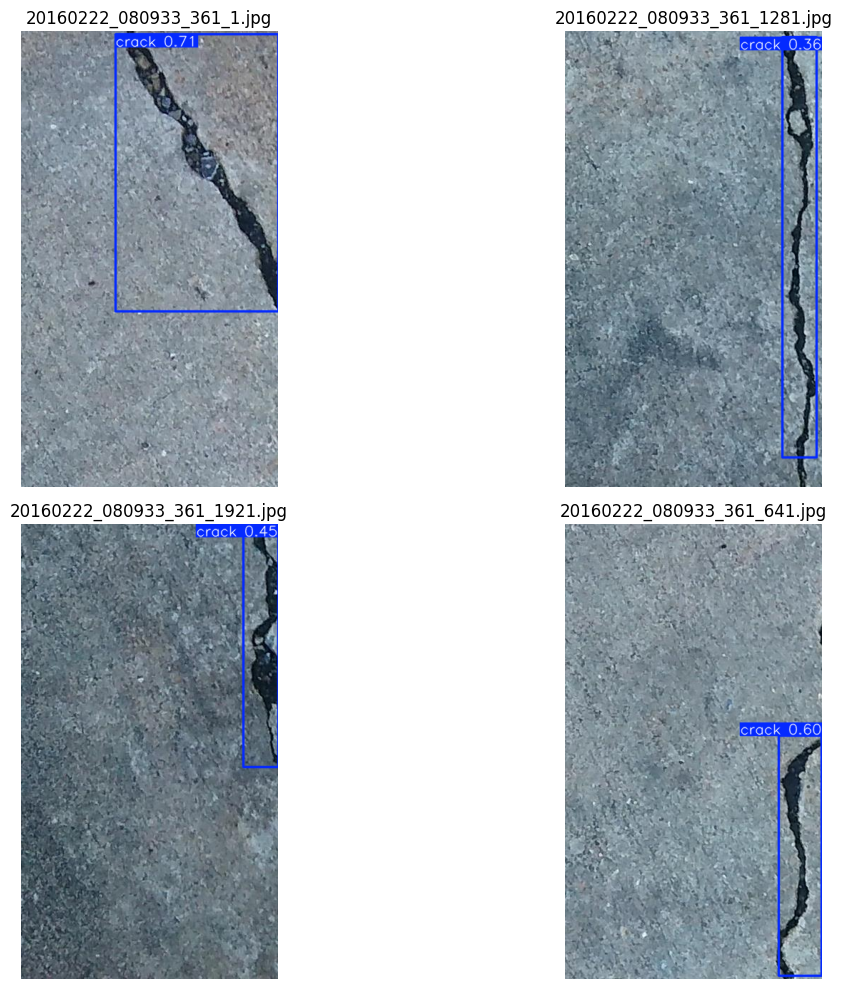

In [ ]:
from pathlib import Path
import matplotlib.pyplot as plt
from PIL import Image

PROJECT_DIR = Path("/content/drive/MyDrive/InfraScan")
YOLO_DIR = PROJECT_DIR / "processed" / "YOLO_CRACK500"

test_images = sorted((YOLO_DIR / "images" / "test").glob("*.jpg"))[:4]

prediction_results = best_yolo_model.predict(
    source=[str(p) for p in test_images],
    imgsz=640,
    conf=0.25,
    save=False
)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, result in zip(axes.flatten(), prediction_results):
    plotted_image = result.plot()
    ax.imshow(plotted_image[:, :, ::-1])
    ax.set_title(Path(result.path).name)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
from pathlib import Path
import shutil

PROJECT_DIR = Path("/content/drive/MyDrive/InfraScan")
RUN_DIR = PROJECT_DIR / "runs" / "crack500_yolo11n"
REPORT_DIR = PROJECT_DIR / "milestone_2_results"

REPORT_DIR.mkdir(parents=True, exist_ok=True)

# Copy training results
for filename in ["results.png", "confusion_matrix.png", "PR_curve.png"]:
    source = RUN_DIR / filename

    if source.exists():
        shutil.copy2(source, REPORT_DIR / filename)
        print("Saved:", filename)
    else:
        print("Not found:", filename)

print("Results folder:", REPORT_DIR)

Saved: results.png
Saved: confusion_matrix.png
Not found: PR_curve.png
Results folder: /content/drive/MyDrive/InfraScan/milestone_2_results


In [ ]:
from pathlib import Path

RUN_DIR = Path("/content/drive/MyDrive/InfraScan/runs/crack500_yolo11n")

for file in sorted(RUN_DIR.glob("*.png")):
    print(file.name)

BoxF1_curve.png
BoxPR_curve.png
BoxP_curve.png
BoxR_curve.png
confusion_matrix.png
confusion_matrix_normalized.png
results.png


In [ ]:
from pathlib import Path
import shutil

PROJECT_DIR = Path("/content/drive/MyDrive/InfraScan")
RUN_DIR = PROJECT_DIR / "runs" / "crack500_yolo11n"
REPORT_DIR = PROJECT_DIR / "milestone_2_results"

plot_names = [
    "results.png",
    "confusion_matrix.png",
    "confusion_matrix_normalized.png",
    "BoxPR_curve.png",
    "BoxP_curve.png",
    "BoxR_curve.png",
    "BoxF1_curve.png"
]

for filename in plot_names:
    source = RUN_DIR / filename

    if source.exists():
        shutil.copy2(source, REPORT_DIR / filename)
        print("Copied:", filename)

print("\nPlots saved in:", REPORT_DIR)

Copied: results.png
Copied: confusion_matrix.png
Copied: confusion_matrix_normalized.png
Copied: BoxPR_curve.png
Copied: BoxP_curve.png
Copied: BoxR_curve.png
Copied: BoxF1_curve.png

Plots saved in: /content/drive/MyDrive/InfraScan/milestone_2_results


U-Net for crack segmentation

In [ ]:
#setup and data check
from pathlib import Path
import cv2
import numpy as np

PROJECT_DIR = Path("/content/drive/MyDrive/InfraScan")
RAW_CROPS_DIR = PROJECT_DIR / "processed" / "YOLO_CRACK500" / "raw_crops"
UNET_DIR = PROJECT_DIR / "processed" / "UNet_CRACK500"

for split in ["traincrop", "valcrop", "testcrop"]:
    split_dir = RAW_CROPS_DIR / split
    images = list(split_dir.rglob("*.jpg"))
    masks = list(split_dir.rglob("*.png"))

    print(f"{split}: {len(images)} images, {len(masks)} masks")

UNET_DIR.mkdir(parents=True, exist_ok=True)
print("U-Net output directory:", UNET_DIR)

traincrop: 1896 images, 1896 masks
valcrop: 348 images, 348 masks
testcrop: 1124 images, 1124 masks
U-Net output directory: /content/drive/MyDrive/InfraScan/processed/UNet_CRACK500


In [ ]:
import tensorflow as tf

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
import cv2
import numpy as np
from pathlib import Path
from tqdm.auto import tqdm

IMG_SIZE = 256

RAW_CROPS_DIR = Path(
    "/content/drive/MyDrive/InfraScan/processed/YOLO_CRACK500/raw_crops"
)
UNET_DIR = Path(
    "/content/drive/MyDrive/InfraScan/processed/UNet_CRACK500"
)

def load_split(split_folder):
    images, masks = [], []

    split_dir = RAW_CROPS_DIR / split_folder
    image_paths = sorted(split_dir.rglob("*.jpg"))

    for image_path in tqdm(image_paths, desc=split_folder):
        mask_path = image_path.with_suffix(".png")

        image = cv2.imread(str(image_path))
        mask = cv2.imread(str(mask_path), cv2.IMREAD_GRAYSCALE)

        if image is None or mask is None:
            continue

        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        image = cv2.resize(image, (IMG_SIZE, IMG_SIZE))
        mask = cv2.resize(
            mask, (IMG_SIZE, IMG_SIZE),
            interpolation=cv2.INTER_NEAREST
        )

        image = image.astype(np.float32) / 255.0
        mask = (mask > 0).astype(np.float32)
        mask = np.expand_dims(mask, axis=-1)

        images.append(image)
        masks.append(mask)

    return np.array(images), np.array(masks)

X_train, y_train = load_split("traincrop")
X_val, y_val = load_split("valcrop")
X_test, y_test = load_split("testcrop")

print("Train:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)

traincrop:   0%|          | 0/1896 [00:00<?, ?it/s]

valcrop:   0%|          | 0/348 [00:00<?, ?it/s]

testcrop:   0%|          | 0/1124 [00:00<?, ?it/s]

Train: (1896, 256, 256, 3) (1896, 256, 256, 1)
Validation: (348, 256, 256, 3) (348, 256, 256, 1)
Test: (1124, 256, 256, 3) (1124, 256, 256, 1)


In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, Model

def conv_block(x, filters):
    x = layers.Conv2D(filters, 3, padding="same", kernel_initializer="he_normal")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)

    x = layers.Conv2D(filters, 3, padding="same", kernel_initializer="he_normal")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)

    return x

def build_unet(input_shape=(256, 256, 3)):
    inputs = layers.Input(shape=input_shape)

    # Encoder
    c1 = conv_block(inputs, 32)
    p1 = layers.MaxPooling2D((2, 2))(c1)

    c2 = conv_block(p1, 64)
    p2 = layers.MaxPooling2D((2, 2))(c2)

    c3 = conv_block(p2, 128)
    p3 = layers.MaxPooling2D((2, 2))(c3)

    c4 = conv_block(p3, 256)
    p4 = layers.MaxPooling2D((2, 2))(c4)

    # Bottleneck
    c5 = conv_block(p4, 512)

    # Decoder
    u6 = layers.Conv2DTranspose(256, 2, strides=2, padding="same")(c5)
    u6 = layers.Concatenate()([u6, c4])
    c6 = conv_block(u6, 256)

    u7 = layers.Conv2DTranspose(128, 2, strides=2, padding="same")(c6)
    u7 = layers.Concatenate()([u7, c3])
    c7 = conv_block(u7, 128)

    u8 = layers.Conv2DTranspose(64, 2, strides=2, padding="same")(c7)
    u8 = layers.Concatenate()([u8, c2])
    c8 = conv_block(u8, 64)

    u9 = layers.Conv2DTranspose(32, 2, strides=2, padding="same")(c8)
    u9 = layers.Concatenate()([u9, c1])
    c9 = conv_block(u9, 32)

    outputs = layers.Conv2D(1, 1, activation="sigmoid")(c9)

    return Model(inputs, outputs, name="UNet_CRACK500")

unet_model = build_unet()

unet_model.summary()

Model: "UNet_CRACK500"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 256, 256,  │        896 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 256, 256,  │        128 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 256, 256,  │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 256, 256,  │      9,248 │ activation[0][0]  │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 256, 256,  │        128 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 256, 256,  │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 128, 128,  │          0 │ activation_1[0][… │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 128, 128,  │     18,496 │ max_pooling2d[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │        256 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 128, 128,  │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 128, 128,  │     36,928 │ activation_2[0][… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │        256 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_3        │ (None, 128, 128,  │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 64, 64,    │          0 │ activation_3[0][… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 64, 64,    │     73,856 │ max_pooling2d_1[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        512 │ conv2d_4[0][0]  

 Total params: 7,771,873 (29.65 MB)

 Trainable params: 7,765,985 (29.62 MB)

 Non-trainable params: 5,888 (23.00 KB)

In [ ]:
import tensorflow as tf
from tensorflow.keras import backend as K

def dice_coefficient(y_true, y_pred, smooth=1e-6):
    y_true = tf.cast(y_true, tf.float32)
    y_pred = tf.cast(y_pred, tf.float32)

    y_true_f = K.flatten(y_true)
    y_pred_f = K.flatten(y_pred)

    intersection = K.sum(y_true_f * y_pred_f)

    return (2.0 * intersection + smooth) / (
        K.sum(y_true_f) + K.sum(y_pred_f) + smooth
    )

def bce_dice_loss(y_true, y_pred):
    bce = tf.keras.losses.binary_crossentropy(y_true, y_pred)
    dice_loss = 1.0 - dice_coefficient(y_true, y_pred)

    return bce + dice_loss

unet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss=bce_dice_loss,
    metrics=[
        dice_coefficient,
        tf.keras.metrics.BinaryIoU(target_class_ids=[1], threshold=0.5, name="crack_iou")
    ]
)

print("U-Net compiled successfully.")

U-Net compiled successfully.


In [ ]:
from pathlib import Path
import tensorflow as tf

UNET_DIR = Path("/content/drive/MyDrive/InfraScan/processed/UNet_CRACK500")
UNET_DIR.mkdir(parents=True, exist_ok=True)

best_model_path = UNET_DIR / "unet_crack500_best.keras"

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(best_model_path),
        monitor="val_dice_coefficient",
        mode="max",
        save_best_only=True,
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_dice_coefficient",
        mode="max",
        patience=8,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-6,
        verbose=1
    )
]

history = unet_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=50,
    batch_size=8,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/50
237/237 ━━━━━━━━━━━━━━━━━━━━ 0s 215ms/step - crack_iou: 0.3002 - dice_coefficient: 0.2537 - loss: 1.1345
Epoch 1: val_dice_coefficient improved from None to 0.33308, saving model to /content/drive/MyDrive/InfraScan/processed/UNet_CRACK500/unet_crack500_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/InfraScan/processed/UNet_CRACK500/unet_crack500_best.keras
237/237 ━━━━━━━━━━━━━━━━━━━━ 117s 267ms/step - crack_iou: 0.4121 - dice_coefficient: 0.3372 - loss: 0.9583 - val_crack_iou: 0.4619 - val_dice_coefficient: 0.3331 - val_loss: 0.8199 - learning_rate: 1.0000e-04
Epoch 2/50
237/237 ━━━━━━━━━━━━━━━━━━━━ 0s 214ms/step - crack_iou: 0.5804 - dice_coefficient: 0.4694 - loss: 0.7001
Epoch 2: val_dice_coefficient improved from 0.33308 to 0.52653, saving model to /content/drive/MyDrive/InfraScan/processed/UNet_CRACK500/unet_crack500_best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/InfraScan/processed/UNet_CRACK500/unet_crack500_best.keras
237/

In [ ]:
# Evaluate the restored best model on the test set
test_results = unet_model.evaluate(
    X_test,
    y_test,
    batch_size=8,
    verbose=1,
    return_dict=True
)

print("\nU-Net Test Results")
for metric, value in test_results.items():
    print(f"{metric}: {value:.4f}")

141/141 ━━━━━━━━━━━━━━━━━━━━ 10s 72ms/step - crack_iou: 0.5408 - dice_coefficient: 0.6667 - loss: 0.4733

U-Net Test Results
crack_iou: 0.5408
dice_coefficient: 0.6667
loss: 0.4733


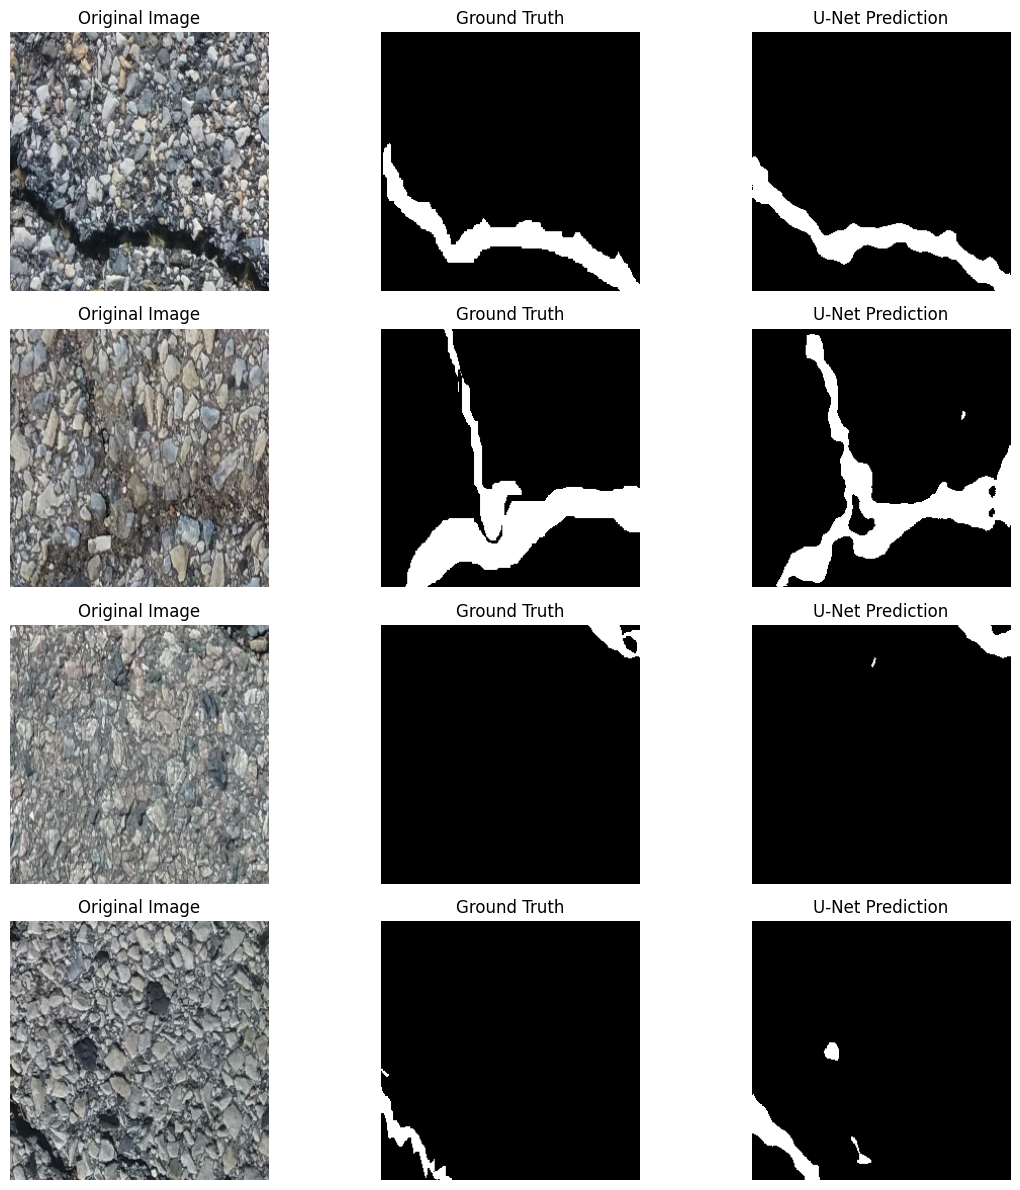

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Display 4 test samples
NUM_SAMPLES = 4
indices = np.random.choice(len(X_test), NUM_SAMPLES, replace=False)

plt.figure(figsize=(12, NUM_SAMPLES * 3))

for row, idx in enumerate(indices):
    image = X_test[idx]
    true_mask = y_test[idx].squeeze()

    pred_mask = unet_model.predict(
        np.expand_dims(image, axis=0),
        verbose=0
    )[0].squeeze()

    pred_binary = (pred_mask > 0.5).astype(np.uint8)

    plt.subplot(NUM_SAMPLES, 3, row * 3 + 1)
    plt.imshow(image)
    plt.title("Original Image")
    plt.axis("off")

    plt.subplot(NUM_SAMPLES, 3, row * 3 + 2)
    plt.imshow(true_mask, cmap="gray")
    plt.title("Ground Truth")
    plt.axis("off")

    plt.subplot(NUM_SAMPLES, 3, row * 3 + 3)
    plt.imshow(pred_binary, cmap="gray")
    plt.title("U-Net Prediction")
    plt.axis("off")

plt.tight_layout()
plt.show()

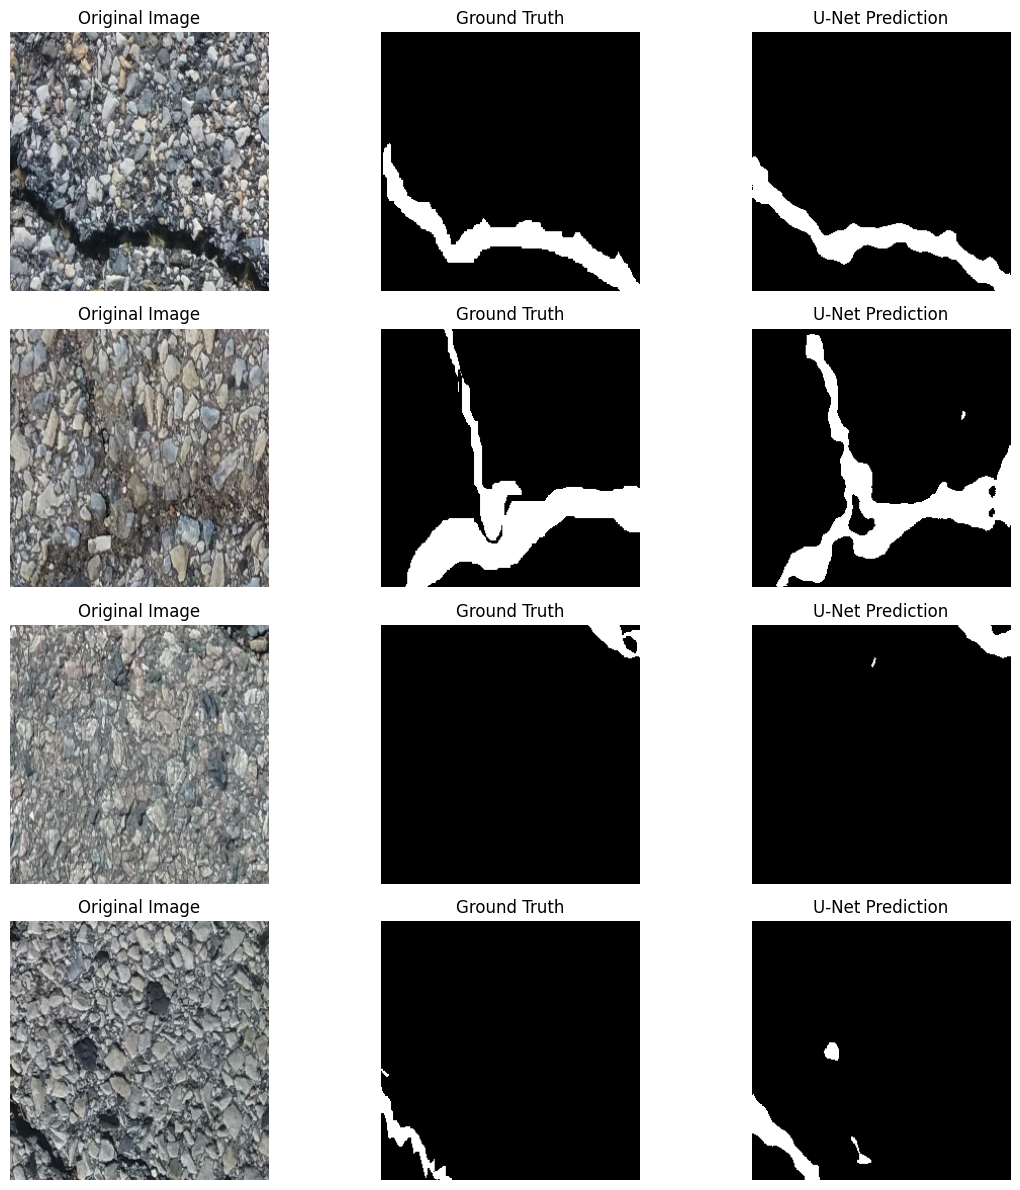

Saved U-Net test metrics and prediction visualization.


In [ ]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import json

RESULTS_DIR = Path(
    "/content/drive/MyDrive/InfraScan/milestone_2_results"
)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Save test metrics
with open(RESULTS_DIR / "unet_test_metrics.json", "w") as f:
    json.dump(
        {key: float(value) for key, value in test_results.items()},
        f,
        indent=4
    )

# Save a visual comparison of the same 4 samples
fig, axes = plt.subplots(NUM_SAMPLES, 3, figsize=(12, NUM_SAMPLES * 3))

for row, idx in enumerate(indices):
    image = X_test[idx]
    true_mask = y_test[idx].squeeze()

    pred_mask = unet_model.predict(
        np.expand_dims(image, axis=0),
        verbose=0
    )[0].squeeze()

    pred_binary = (pred_mask > 0.5).astype(np.uint8)

    axes[row, 0].imshow(image)
    axes[row, 0].set_title("Original Image")

    axes[row, 1].imshow(true_mask, cmap="gray")
    axes[row, 1].set_title("Ground Truth")

    axes[row, 2].imshow(pred_binary, cmap="gray")
    axes[row, 2].set_title("U-Net Prediction")

    for ax in axes[row]:
        ax.axis("off")

plt.tight_layout()
plt.savefig(
    RESULTS_DIR / "unet_test_predictions.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("Saved U-Net test metrics and prediction visualization.")

In [ ]:
from pathlib import Path

UNET_DIR = Path(
    "/content/drive/MyDrive/InfraScan/processed/UNet_CRACK500"
)

for file in UNET_DIR.iterdir():
    if file.is_file():
        print(file.name, f"({file.stat().st_size / (1024 * 1024):.2f} MB)")

unet_crack500_best.keras (89.19 MB)


In [ ]:
import tensorflow as tf
from pathlib import Path

model_path = Path(
    "/content/drive/MyDrive/InfraScan/processed/UNet_CRACK500/unet_crack500_best.keras"
)

loaded_unet = tf.keras.models.load_model(
    model_path,
    custom_objects={
        "bce_dice_loss": bce_dice_loss,
        "dice_coefficient": dice_coefficient
    }
)

print("Model loaded successfully.")
print("Input shape:", loaded_unet.input_shape)
print("Output shape:", loaded_unet.output_shape)


Model loaded successfully.
Input shape: (None, 256, 256, 3)
Output shape: (None, 256, 256, 1)


CNN crack-classification baseline.

In [ ]:
from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/InfraScan")
DATASET_DIR = PROJECT_DIR / "datasets"

print("Dataset directory exists:", DATASET_DIR.exists())

for path in sorted(DATASET_DIR.iterdir()):
    print(path.name, "—", "Directory" if path.is_dir() else "File")

Dataset directory exists: False


FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/InfraScan/datasets'

In [ ]:
from pathlib import Path

CLASSIFICATION_DIR = (
    PROJECT_DIR / "datasets" / "Concrete_Crack_Classification"
)

for path in sorted(CLASSIFICATION_DIR.iterdir()):
    if path.is_dir():
        image_count = sum(
            1 for file in path.rglob("*")
            if file.suffix.lower() in {".jpg", ".jpeg", ".png"}
        )
        print(f"{path.name}: {image_count} images")
    else:
        print(path.name)

Negative: 3691 images
Positive: 20000 images


In [ ]:
#stratified train/validation/test split
from pathlib import Path

for class_name in ["Negative", "Positive"]:
    class_dir = CLASSIFICATION_DIR / class_name
    samples = list(class_dir.iterdir())[:5]

    print(f"\n{class_name}:")
    for sample in samples:
        print(sample.name, "—", "Directory" if sample.is_dir() else "File")


Negative:
02692.jpg — File
02693.jpg — File
02694.jpg — File
02695.jpg — File
02696.jpg — File

Positive:
19001_1.jpg — File
19002_1.jpg — File
19003_1.jpg — File
19004_1.jpg — File
19005_1.jpg — File


In [ ]:
import tensorflow as tf
from pathlib import Path
from sklearn.model_selection import train_test_split
import numpy as np

IMG_SIZE = (128, 128)
SEED = 42

# Collect paths and labels
image_paths = []
labels = []

class_mapping = {
    "Negative": 0,
    "Positive": 1
}

for class_name, label in class_mapping.items():
    class_dir = CLASSIFICATION_DIR / class_name

    for path in class_dir.iterdir():
        if path.suffix.lower() in {".jpg", ".jpeg", ".png"}:
            image_paths.append(str(path))
            labels.append(label)

image_paths = np.array(image_paths)
labels = np.array(labels)

# 70% train, 30% temporary
X_train_paths, X_temp_paths, y_train, y_temp = train_test_split(
    image_paths,
    labels,
    test_size=0.30,
    stratify=labels,
    random_state=SEED
)

# Split temporary into 15% validation and 15% test
X_val_paths, X_test_paths, y_val, y_test = train_test_split(
    X_temp_paths,
    y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=SEED
)

print("Train:", len(X_train_paths))
print("Validation:", len(X_val_paths))
print("Test:", len(X_test_paths))

print("\nClass mapping:", class_mapping)
print("\nTrain distribution:", np.bincount(y_train))
print("Validation distribution:", np.bincount(y_val))
print("Test distribution:", np.bincount(y_test))

Train: 16583
Validation: 3554
Test: 3554

Class mapping: {'Negative': 0, 'Positive': 1}

Train distribution: [ 2584 13999]
Validation distribution: [ 553 3001]
Test distribution: [ 554 3000]


In [ ]:
import tensorflow as tf

IMG_SIZE = (128, 128)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

def load_image(path, label):
    image = tf.io.read_file(path)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32) / 255.0

    label = tf.cast(label, tf.float32)
    return image, label

def create_dataset(paths, labels, training=False):
    dataset = tf.data.Dataset.from_tensor_slices((paths, labels))

    if training:
        dataset = dataset.shuffle(
            buffer_size=len(paths),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    dataset = dataset.map(
        load_image,
        num_parallel_calls=AUTOTUNE
    )

    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(AUTOTUNE)

    return dataset

train_ds = create_dataset(X_train_paths, y_train, training=True)
val_ds = create_dataset(X_val_paths, y_val)
test_ds = create_dataset(X_test_paths, y_test)

print("TensorFlow datasets created.")

TensorFlow datasets created.


In [ ]:
import tensorflow as tf
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

# Calculate class weights from training labels only
classes = np.array([0, 1])

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights = {
    int(cls): float(weight)
    for cls, weight in zip(classes, weights)
}

print("Class weights:", class_weights)

# Build CNN classifier
cnn_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(128, 128, 3)),

    tf.keras.layers.Conv2D(32, 3, padding="same", activation="relu"),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Conv2D(64, 3, padding="same", activation="relu"),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Conv2D(128, 3, padding="same", activation="relu"),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Conv2D(256, 3, padding="same", activation="relu"),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.5),

    # Output: probability of Positive (crack)
    tf.keras.layers.Dense(1, activation="sigmoid")
])

cnn_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)

cnn_model.summary()

Class weights: {0: 3.2087848297213624, 1: 0.5922923065933281}


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_19 (Conv2D)              │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_20 (Conv2D)              │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_21 (Conv2D)              │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_22 (Conv2D)              │ (None, 16, 16, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 421,441 (1.61 MB)

 Trainable params: 421,441 (1.61 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
#training
from pathlib import Path
import tensorflow as tf

CNN_DIR = (
    Path("/content/drive/MyDrive/InfraScan/processed/CNN_Classification")
)
CNN_DIR.mkdir(parents=True, exist_ok=True)

best_cnn_path = CNN_DIR / "cnn_crack_classifier_best.keras"

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(best_cnn_path),
        monitor="val_loss",
        save_best_only=True,
        mode="min",
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6,
        verbose=1
    )
]

cnn_history = cnn_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=30,
    class_weight=class_weights,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/30
519/519 ━━━━━━━━━━━━━━━━━━━━ 0s 5s/step - accuracy: 0.8538 - loss: 0.3297 - precision: 0.9547 - recall: 0.8632
Epoch 1: val_loss improved from None to 0.32112, saving model to /content/drive/MyDrive/InfraScan/processed/CNN_Classification/cnn_crack_classifier_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/InfraScan/processed/CNN_Classification/cnn_crack_classifier_best.keras
519/519 ━━━━━━━━━━━━━━━━━━━━ 3108s 6s/step - accuracy: 0.9323 - loss: 0.1854 - precision: 0.9847 - recall: 0.9344 - val_accuracy: 0.9018 - val_loss: 0.3211 - val_precision: 1.0000 - val_recall: 0.8837 - learning_rate: 0.0010
Epoch 2/30
518/519 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step - accuracy: 0.9657 - loss: 0.0965 - precision: 0.9955 - recall: 0.9639
Epoch 2: val_loss improved from 0.32112 to 0.16132, saving model to /content/drive/MyDrive/InfraScan/processed/CNN_Classification/cnn_crack_classifier_best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/InfraScan/processed/C

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
import numpy as np
import tensorflow as tf

PROJECT_DIR = Path("/content/drive/MyDrive/InfraScan")
DATASET_DIR = PROJECT_DIR / "datasets"
CLASSIFICATION_DIR = DATASET_DIR / "Concrete_Crack_Classification"

CNN_DIR = PROJECT_DIR / "processed" / "CNN_Classification"
best_cnn_path = CNN_DIR / "cnn_crack_classifier_best.keras"

print("Checkpoint exists:", best_cnn_path.exists())

Mounted at /content/drive
Checkpoint exists: True


In [ ]:
from sklearn.model_selection import train_test_split

IMG_SIZE = (128, 128)
BATCH_SIZE = 32
SEED = 42
AUTOTUNE = tf.data.AUTOTUNE

image_paths = []
labels = []

class_mapping = {
    "Negative": 0,
    "Positive": 1
}

for class_name, label in class_mapping.items():
    class_dir = CLASSIFICATION_DIR / class_name

    for path in class_dir.iterdir():
        if path.suffix.lower() in {".jpg", ".jpeg", ".png"}:
            image_paths.append(str(path))
            labels.append(label)

image_paths = np.array(image_paths)
labels = np.array(labels)

X_train_paths, X_temp_paths, y_train, y_temp = train_test_split(
    image_paths,
    labels,
    test_size=0.30,
    stratify=labels,
    random_state=SEED
)

X_val_paths, X_test_paths, y_val, y_test = train_test_split(
    X_temp_paths,
    y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=SEED
)

print("Train:", len(X_train_paths))
print("Validation:", len(X_val_paths))
print("Test:", len(X_test_paths))

Train: 16583
Validation: 3554
Test: 3554


In [ ]:
def load_image(path, label):
    image = tf.io.read_file(path)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32) / 255.0

    return image, tf.cast(label, tf.float32)

def create_dataset(paths, labels, training=False):
    dataset = tf.data.Dataset.from_tensor_slices((paths, labels))

    if training:
        dataset = dataset.shuffle(
            buffer_size=len(paths),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    dataset = dataset.map(
        load_image,
        num_parallel_calls=AUTOTUNE
    )

    return dataset.batch(BATCH_SIZE).prefetch(AUTOTUNE)

test_ds = create_dataset(X_test_paths, y_test)

print("Test dataset recreated.")

Test dataset recreated.


In [ ]:
cnn_model = tf.keras.models.load_model(best_cnn_path)

print("CNN checkpoint loaded.")
print("Input shape:", cnn_model.input_shape)
print("Output shape:", cnn_model.output_shape)

CNN checkpoint loaded.
Input shape: (None, 128, 128, 3)
Output shape: (None, 1)


112/112 ━━━━━━━━━━━━━━━━━━━━ 766s 7s/step
Test Accuracy: 0.9969

Classification Report:
                     precision    recall  f1-score   support

Negative (No Crack)     0.9840    0.9964    0.9901       554
   Positive (Crack)     0.9993    0.9970    0.9982      3000

           accuracy                         0.9969      3554
          macro avg     0.9916    0.9967    0.9941      3554
       weighted avg     0.9969    0.9969    0.9969      3554



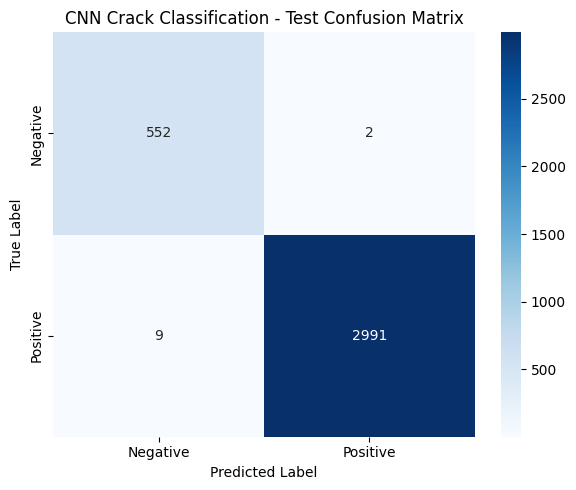

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score
)

y_prob = cnn_model.predict(test_ds, verbose=1).ravel()
y_pred = (y_prob >= 0.5).astype(int)

y_true = np.concatenate([
    batch_labels.numpy() for _, batch_labels in test_ds
]).astype(int)

print("Test Accuracy:", round(accuracy_score(y_true, y_pred), 4))

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    target_names=["Negative (No Crack)", "Positive (Crack)"],
    digits=4
))

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negative", "Positive"],
    yticklabels=["Negative", "Positive"]
)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("CNN Crack Classification - Test Confusion Matrix")
plt.tight_layout()
plt.show()

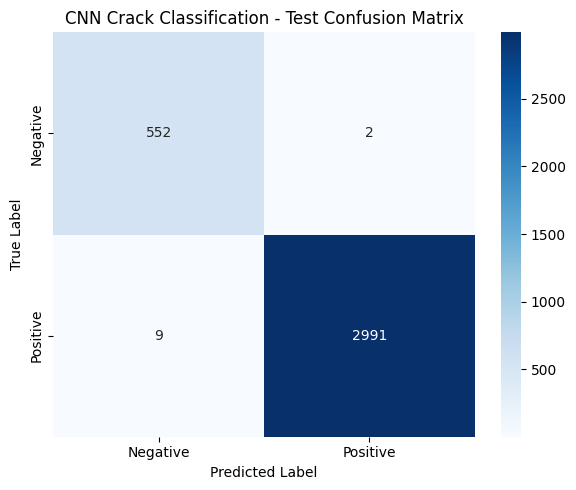

CNN classification report saved.
CNN confusion matrix saved.
Training history skipped because the runtime restarted.


In [ ]:
from pathlib import Path
import json
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import classification_report, confusion_matrix

RESULTS_DIR = Path(
    "/content/drive/MyDrive/InfraScan/milestone_2_results"
)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Save classification report
report = classification_report(
    y_true,
    y_pred,
    target_names=["Negative (No Crack)", "Positive (Crack)"],
    output_dict=True,
    digits=4
)

with open(RESULTS_DIR / "cnn_classification_report.json", "w") as f:
    json.dump(report, f, indent=4)

# Save confusion matrix
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negative", "Positive"],
    yticklabels=["Negative", "Positive"]
)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("CNN Crack Classification - Test Confusion Matrix")
plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "cnn_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("CNN classification report saved.")
print("CNN confusion matrix saved.")
print("Training history skipped because the runtime restarted.")

In [ ]:
from pathlib import Path

BASE_DIR = Path("/content/drive/MyDrive/InfraScan")

print("Project directory exists:", BASE_DIR.exists())
if BASE_DIR.exists():
    print("Project contents:")
    for item in BASE_DIR.iterdir():
        print("-", item.name)

Project directory exists: True
Project contents:
- datasets
- manifests
- processed
- eda_results
- runs
- milestone_2_results


In [ ]:
from pathlib import Path
import os

BASE_DIR = Path("/content/drive/MyDrive/InfraScan")

print("Project directory exists:", BASE_DIR.exists())
print("Results directory exists:", (BASE_DIR / "milestone_2_results").exists())
print("U-Net model exists:", (BASE_DIR / "processed/UNet_CRACK500/unet_crack500_best.keras").exists())
print("YOLO model exists:", (BASE_DIR / "runs/crack500_yolo11n/weights/best.pt").exists())
print("CNN model exists:", (BASE_DIR / "processed/CNN_Classification/cnn_crack_classifier_best.keras").exists())

Project directory exists: True
Results directory exists: True
U-Net model exists: True
YOLO model exists: True
CNN model exists: True


In [ ]:
from pathlib import Path

BASE_DIR = Path("/content/drive/MyDrive/InfraScan")

for folder in [
    BASE_DIR / "processed/UNet_CRACK500",
    BASE_DIR / "processed/YOLO_CRACK500",
    BASE_DIR / "milestone_2_results",
]:
    print(f"\n--- {folder} ---")
    if folder.exists():
        for item in list(folder.iterdir())[:20]:
            print(item.name)
    else:
        print("Folder not found")


--- /content/drive/MyDrive/InfraScan/processed/UNet_CRACK500 ---
unet_crack500_best.keras

--- /content/drive/MyDrive/InfraScan/processed/YOLO_CRACK500 ---
raw_crops
images
labels
data.yaml

--- /content/drive/MyDrive/InfraScan/milestone_2_results ---
BoxPR_curve.png
BoxR_curve.png
BoxP_curve.png
BoxF1_curve.png
confusion_matrix_normalized.png
results.png
confusion_matrix.png
unet_test_metrics.json
unet_test_predictions.png
cnn_classification_report.json
cnn_confusion_matrix.png


In [ ]:
from pathlib import Path

YOLO_DIR = BASE_DIR / "processed/YOLO_CRACK500"

for folder in [YOLO_DIR / "images", YOLO_DIR / "raw_crops"]:
    print(f"\n{folder}")
    if folder.exists():
        for item in folder.iterdir():
            print(item.name, "—", "directory" if item.is_dir() else "file")


/content/drive/MyDrive/InfraScan/processed/YOLO_CRACK500/images
train — directory
val — directory
test — directory

/content/drive/MyDrive/InfraScan/processed/YOLO_CRACK500/raw_crops
traincrop — directory
valcrop — directory
testcrop — directory


In [ ]:
from pathlib import Path

YOLO_DIR = BASE_DIR / "processed/YOLO_CRACK500"

for split in ["train", "val", "test"]:
    image_dir = YOLO_DIR / "images" / split
    label_dir = YOLO_DIR / "labels" / split

    images = list(image_dir.glob("*")) if image_dir.exists() else []
    labels = list(label_dir.glob("*.txt")) if label_dir.exists() else []

    image_stems = {p.stem for p in images if p.is_file()}
    label_stems = {p.stem for p in labels}

    print(f"\n{split.upper()}")
    print("Images:", len(image_stems))
    print("Labels:", len(label_stems))
    print("Images without labels:", len(image_stems - label_stems))
    print("Labels without images:", len(label_stems - image_stems))


TRAIN
Images: 1896
Labels: 1896
Images without labels: 0
Labels without images: 0

VAL
Images: 348
Labels: 348
Images without labels: 0
Labels without images: 0

TEST
Images: 1124
Labels: 1124
Images without labels: 0
Labels without images: 0


In [ ]:
#image quality assessment
import cv2
import pandas as pd
import numpy as np
from pathlib import Path
from tqdm.auto import tqdm

YOLO_DIR = BASE_DIR / "processed/YOLO_CRACK500"
RESULTS_DIR = BASE_DIR / "milestone_2_results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

quality_records = []

for split in ["train", "val", "test"]:
    image_dir = YOLO_DIR / "images" / split

    for image_path in tqdm(
        list(image_dir.iterdir()),
        desc=f"Assessing {split}"
    ):
        if not image_path.is_file():
            continue

        image = cv2.imread(str(image_path))

        if image is None:
            quality_records.append({
                "split": split,
                "filename": image_path.name,
                "readable": False
            })
            continue

        gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

        quality_records.append({
            "split": split,
            "filename": image_path.name,
            "readable": True,
            "width": image.shape[1],
            "height": image.shape[0],
            "brightness_mean": float(np.mean(gray)),
            "contrast_std": float(np.std(gray)),
            "blur_score": float(cv2.Laplacian(gray, cv2.CV_64F).var())
        })

quality_df = pd.DataFrame(quality_records)

quality_csv = RESULTS_DIR / "image_quality_assessment.csv"
quality_df.to_csv(quality_csv, index=False)

print("Images assessed:", len(quality_df))
print("Unreadable images:", (~quality_df["readable"]).sum())

print("\nQuality summary:")
display(
    quality_df[quality_df["readable"]]
    .groupby("split")[[
        "width", "height",
        "brightness_mean", "contrast_std", "blur_score"
    ]]
    .agg(["mean", "min", "max"])
    .round(2)
)

print("\nSaved to:", quality_csv)

Assessing train:   0%|          | 0/1896 [00:00<?, ?it/s]

Assessing val:   0%|          | 0/348 [00:00<?, ?it/s]

Assessing test:   0%|          | 0/1124 [00:00<?, ?it/s]

Images assessed: 3368
Unreadable images: 0

Quality summary:


width            height           brightness_mean                 \
         mean  min  max    mean  min  max            mean    min     max   
split                                                                      
test   635.27  360  640  364.73  360  640          125.43  92.55  152.35   
train  627.54  360  648  376.36  360  640          126.37  80.51  157.99   
val    634.76  360  648  371.69  360  640          127.24  97.28  153.69   

      contrast_std               blur_score                   
              mean    min    max       mean     min      max  
split                                                         
test         44.22  13.82  76.06    1773.66   76.87  6466.96  
train        40.51   8.67  75.45    1541.46   32.85  8179.23  
val          38.76  18.92  71.87    1412.14  134.85  7282.15


Saved to: /content/drive/MyDrive/InfraScan/milestone_2_results/image_quality_assessment.csv


In [ ]:
#crack geometry extraction from U-Net predicted masks
from pathlib import Path

BASE_DIR = Path("/content/drive/MyDrive/InfraScan")

for root in [
    BASE_DIR / "processed/UNet_CRACK500",
    BASE_DIR / "datasets",
]:
    print(f"\n--- {root} ---")
    if root.exists():
        for path in sorted(root.iterdir()):
            print(path.name, "—", "directory" if path.is_dir() else "file")


--- /content/drive/MyDrive/InfraScan/processed/UNet_CRACK500 ---
unet_crack500_best.keras — file

--- /content/drive/MyDrive/InfraScan/datasets ---
5y9wdsg2zt-2.zip — file
Concrete Crack Images for Classification.rar — file
Concrete_Crack_Classification — directory
CrackForest-dataset-master.zip — file
DATA_Maguire_20180517_ALL.zip — file
archive.zip — file


In [ ]:
from pathlib import Path
import zipfile

BASE_DIR = Path("/content/drive/MyDrive/InfraScan")
DATA_DIR = BASE_DIR / "datasets"

for archive in DATA_DIR.glob("*.zip"):
    print(f"\n--- {archive.name} ---")
    try:
        with zipfile.ZipFile(archive) as z:
            names = z.namelist()
            crack_entries = [
                name for name in names
                if "crack500" in name.lower()
                or "crack_500" in name.lower()
            ]
            print("Total entries:", len(names))
            print("CRACK500-related entries:", len(crack_entries))
            for name in crack_entries[:15]:
                print(name)
    except zipfile.BadZipFile:
        print("Not a readable ZIP archive.")


--- DATA_Maguire_20180517_ALL.zip ---
Total entries: 2
CRACK500-related entries: 0

--- 5y9wdsg2zt-2.zip ---
Total entries: 1
CRACK500-related entries: 0

--- CrackForest-dataset-master.zip ---
Total entries: 397
CRACK500-related entries: 0

--- archive.zip ---
Total entries: 10487
CRACK500-related entries: 10487
CRACK500/fphb_testresult/hed_fuse_fpn_ada_python_v1_iter_12000/20160222_080933_361_1.mat
CRACK500/fphb_testresult/hed_fuse_fpn_ada_python_v1_iter_12000/20160222_080933_361_1.png
CRACK500/fphb_testresult/hed_fuse_fpn_ada_python_v1_iter_12000/20160222_080933_361_1281.mat
CRACK500/fphb_testresult/hed_fuse_fpn_ada_python_v1_iter_12000/20160222_080933_361_1281.png
CRACK500/fphb_testresult/hed_fuse_fpn_ada_python_v1_iter_12000/20160222_080933_361_1921.mat
CRACK500/fphb_testresult/hed_fuse_fpn_ada_python_v1_iter_12000/20160222_080933_361_1921.png
CRACK500/fphb_testresult/hed_fuse_fpn_ada_python_v1_iter_12000/20160222_080933_361_641.mat
CRACK500/fphb_testresult/hed_fuse_fpn_ada_pytho

In [ ]:
import zipfile
from collections import Counter

archive_path = DATA_DIR / "archive.zip"

with zipfile.ZipFile(archive_path) as z:
    names = z.namelist()

    top_folders = Counter(
        name.split("/")[1]
        for name in names
        if name.startswith("CRACK500/") and len(name.split("/")) > 1
    )

    print("Top-level CRACK500 folders:")
    for folder, count in top_folders.most_common():
        print(f"{folder}: {count}")

    print("\nLikely image/mask paths:")
    matches = [
        name for name in names
        if any(term in name.lower() for term in [
            "groundtruth", "ground_truth", "mask", "label",
            "image", "crop"
        ])
        and name.lower().endswith((".png", ".jpg", ".jpeg", ".mat"))
    ]

    for name in matches[:60]:
        print(name)

    print("\nTotal likely image/mask files:", len(matches))

Top-level CRACK500 folders:
traincrop: 3792
fphb_testresult: 2248
testcrop: 2248
traindata: 800
valcrop: 696
testdata: 600
valdata: 100
test.txt: 1
train.txt: 1
val.txt: 1

Likely image/mask paths:
CRACK500/testcrop/testcrop/20160222_080933_361_1.jpg
CRACK500/testcrop/testcrop/20160222_080933_361_1.png
CRACK500/testcrop/testcrop/20160222_080933_361_1281.jpg
CRACK500/testcrop/testcrop/20160222_080933_361_1281.png
CRACK500/testcrop/testcrop/20160222_080933_361_1921.jpg
CRACK500/testcrop/testcrop/20160222_080933_361_1921.png
CRACK500/testcrop/testcrop/20160222_080933_361_641.jpg
CRACK500/testcrop/testcrop/20160222_080933_361_641.png
CRACK500/testcrop/testcrop/20160222_080933_721_1.jpg
CRACK500/testcrop/testcrop/20160222_080933_721_1.png
CRACK500/testcrop/testcrop/20160222_080933_721_1921.jpg
CRACK500/testcrop/testcrop/20160222_080933_721_1921.png
CRACK500/testcrop/testcrop/20160222_080933_721_641.jpg
CRACK500/testcrop/testcrop/20160222_080933_721_641.png
CRACK500/testcrop/testcrop/2016022

Test crop JPG images: 1124
Test crop PNG annotations: 1124
Matched pairs: 1124
JPG without PNG: 0
PNG without JPG: 0

Sample pair: 20160222_080933_361_1
Image dimensions: (360, 640)
Mask dimensions: (360, 640)
Mask mode: 1
Mask unique pixel values: [False  True]
Mask pixel-value counts: [(np.False_, 218103), (np.True_, 12297)]


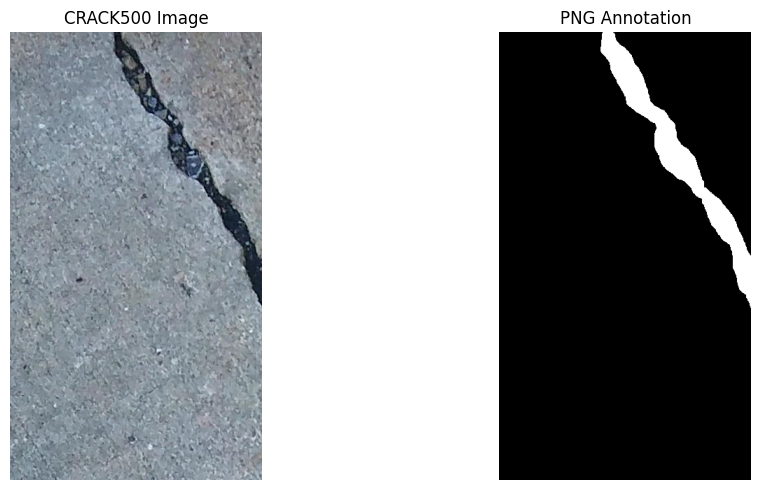

In [ ]:
import zipfile
from pathlib import PurePosixPath
from collections import Counter
from PIL import Image
import io
import numpy as np
import matplotlib.pyplot as plt

archive_path = DATA_DIR / "archive.zip"

with zipfile.ZipFile(archive_path) as z:
    # Check image/mask pairs from the test crop folder
    folder = "CRACK500/testcrop/testcrop/"
    files = z.namelist()

    jpg_names = {
        PurePosixPath(name).stem: name
        for name in files
        if name.startswith(folder) and name.lower().endswith(".jpg")
    }

    png_names = {
        PurePosixPath(name).stem: name
        for name in files
        if name.startswith(folder) and name.lower().endswith(".png")
    }

    paired = sorted(set(jpg_names) & set(png_names))
    jpg_only = sorted(set(jpg_names) - set(png_names))
    png_only = sorted(set(png_names) - set(jpg_names))

    print("Test crop JPG images:", len(jpg_names))
    print("Test crop PNG annotations:", len(png_names))
    print("Matched pairs:", len(paired))
    print("JPG without PNG:", len(jpg_only))
    print("PNG without JPG:", len(png_only))

    if paired:
        sample_id = paired[0]

        image = Image.open(io.BytesIO(z.read(jpg_names[sample_id]))).convert("RGB")
        mask = Image.open(io.BytesIO(z.read(png_names[sample_id])))

        image_array = np.array(image)
        mask_array = np.array(mask)

        print("\nSample pair:", sample_id)
        print("Image dimensions:", image.size)
        print("Mask dimensions:", mask.size)
        print("Mask mode:", mask.mode)
        print("Mask unique pixel values:", np.unique(mask_array)[:30])
        print("Mask pixel-value counts:", Counter(mask_array.flatten()).most_common(10))

        plt.figure(figsize=(12, 5))

        plt.subplot(1, 2, 1)
        plt.imshow(image_array)
        plt.title("CRACK500 Image")
        plt.axis("off")

        plt.subplot(1, 2, 2)
        plt.imshow(mask_array, cmap="gray")
        plt.title("PNG Annotation")
        plt.axis("off")

        plt.tight_layout()
        plt.show()

In [ ]:
import tensorflow as tf

def bce_dice_loss(y_true, y_pred):
    bce = tf.keras.backend.binary_crossentropy(y_true, y_pred)

    intersection = tf.reduce_sum(y_true * y_pred, axis=[1, 2, 3])
    denominator = (
        tf.reduce_sum(y_true, axis=[1, 2, 3])
        + tf.reduce_sum(y_pred, axis=[1, 2, 3])
    )

    dice = (2.0 * intersection + 1e-7) / (denominator + 1e-7)
    dice_loss = 1.0 - dice

    return tf.reduce_mean(bce) + tf.reduce_mean(dice_loss)


def dice_coefficient(y_true, y_pred):
    intersection = tf.reduce_sum(y_true * y_pred, axis=[1, 2, 3])
    denominator = (
        tf.reduce_sum(y_true, axis=[1, 2, 3])
        + tf.reduce_sum(y_pred, axis=[1, 2, 3])
    )

    dice = (2.0 * intersection + 1e-7) / (denominator + 1e-7)
    return tf.reduce_mean(dice)


unet_model = tf.keras.models.load_model(
    MODEL_PATH,
    custom_objects={
        "bce_dice_loss": bce_dice_loss,
        "dice_coefficient": dice_coefficient
    }
)

print("Model loaded successfully.")
print("Input shape:", unet_model.input_shape)
print("Output shape:", unet_model.output_shape)

Model loaded successfully.
Input shape: (None, 256, 256, 3)
Output shape: (None, 256, 256, 1)


In [ ]:
import json
import numpy as np
from sklearn.metrics import confusion_matrix

RESULTS_DIR = PROJECT_DIR / "milestone_2_results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

y_pred_prob = unet_model.predict(X_test, batch_size=16, verbose=1)
y_pred = (y_pred_prob >= 0.5).astype(np.uint8)
y_true = (y_test >= 0.5).astype(np.uint8)

intersection = np.sum(y_true * y_pred)
union = np.sum(y_true) + np.sum(y_pred) - intersection

iou = intersection / (union + 1e-7)
dice = (2 * intersection) / (np.sum(y_true) + np.sum(y_pred) + 1e-7)

tn, fp, fn, tp = confusion_matrix(
    y_true.flatten(), y_pred.flatten(), labels=[0, 1]
).ravel()

pixel_accuracy = (tp + tn) / (tp + tn + fp + fn)
precision = tp / (tp + fp + 1e-7)
recall = tp / (tp + fn + 1e-7)

metrics = {
    "test_iou": float(iou),
    "test_dice": float(dice),
    "test_pixel_accuracy": float(pixel_accuracy),
    "test_precision": float(precision),
    "test_recall": float(recall),
    "test_TN": int(tn),
    "test_FP": int(fp),
    "test_FN": int(fn),
    "test_TP": int(tp),
    "threshold": 0.5,
    "input_size": 256
}

metrics_path = RESULTS_DIR / "unet_test_metrics_verified.json"

with open(metrics_path, "w") as f:
    json.dump(metrics, f, indent=4)

print("\nVerified U-Net Test Metrics:")
for key, value in metrics.items():
    print(f"{key}: {value}")

print("\nSaved to:", metrics_path)

71/71 ━━━━━━━━━━━━━━━━━━━━ 17s 135ms/step

Verified U-Net Test Metrics:
test_iou: 0.5408209063448854
test_dice: 0.70199061307886
test_pixel_accuracy: 0.9673754193180396
test_precision: 0.717197510975235
test_recall: 0.6874151962080592
test_TN: 68428761
test_FP: 1116110
test_FN: 1287097
test_TP: 2830496
threshold: 0.5
input_size: 256

Saved to: /content/drive/MyDrive/InfraScan/milestone_2_results/unet_test_metrics_verified.json


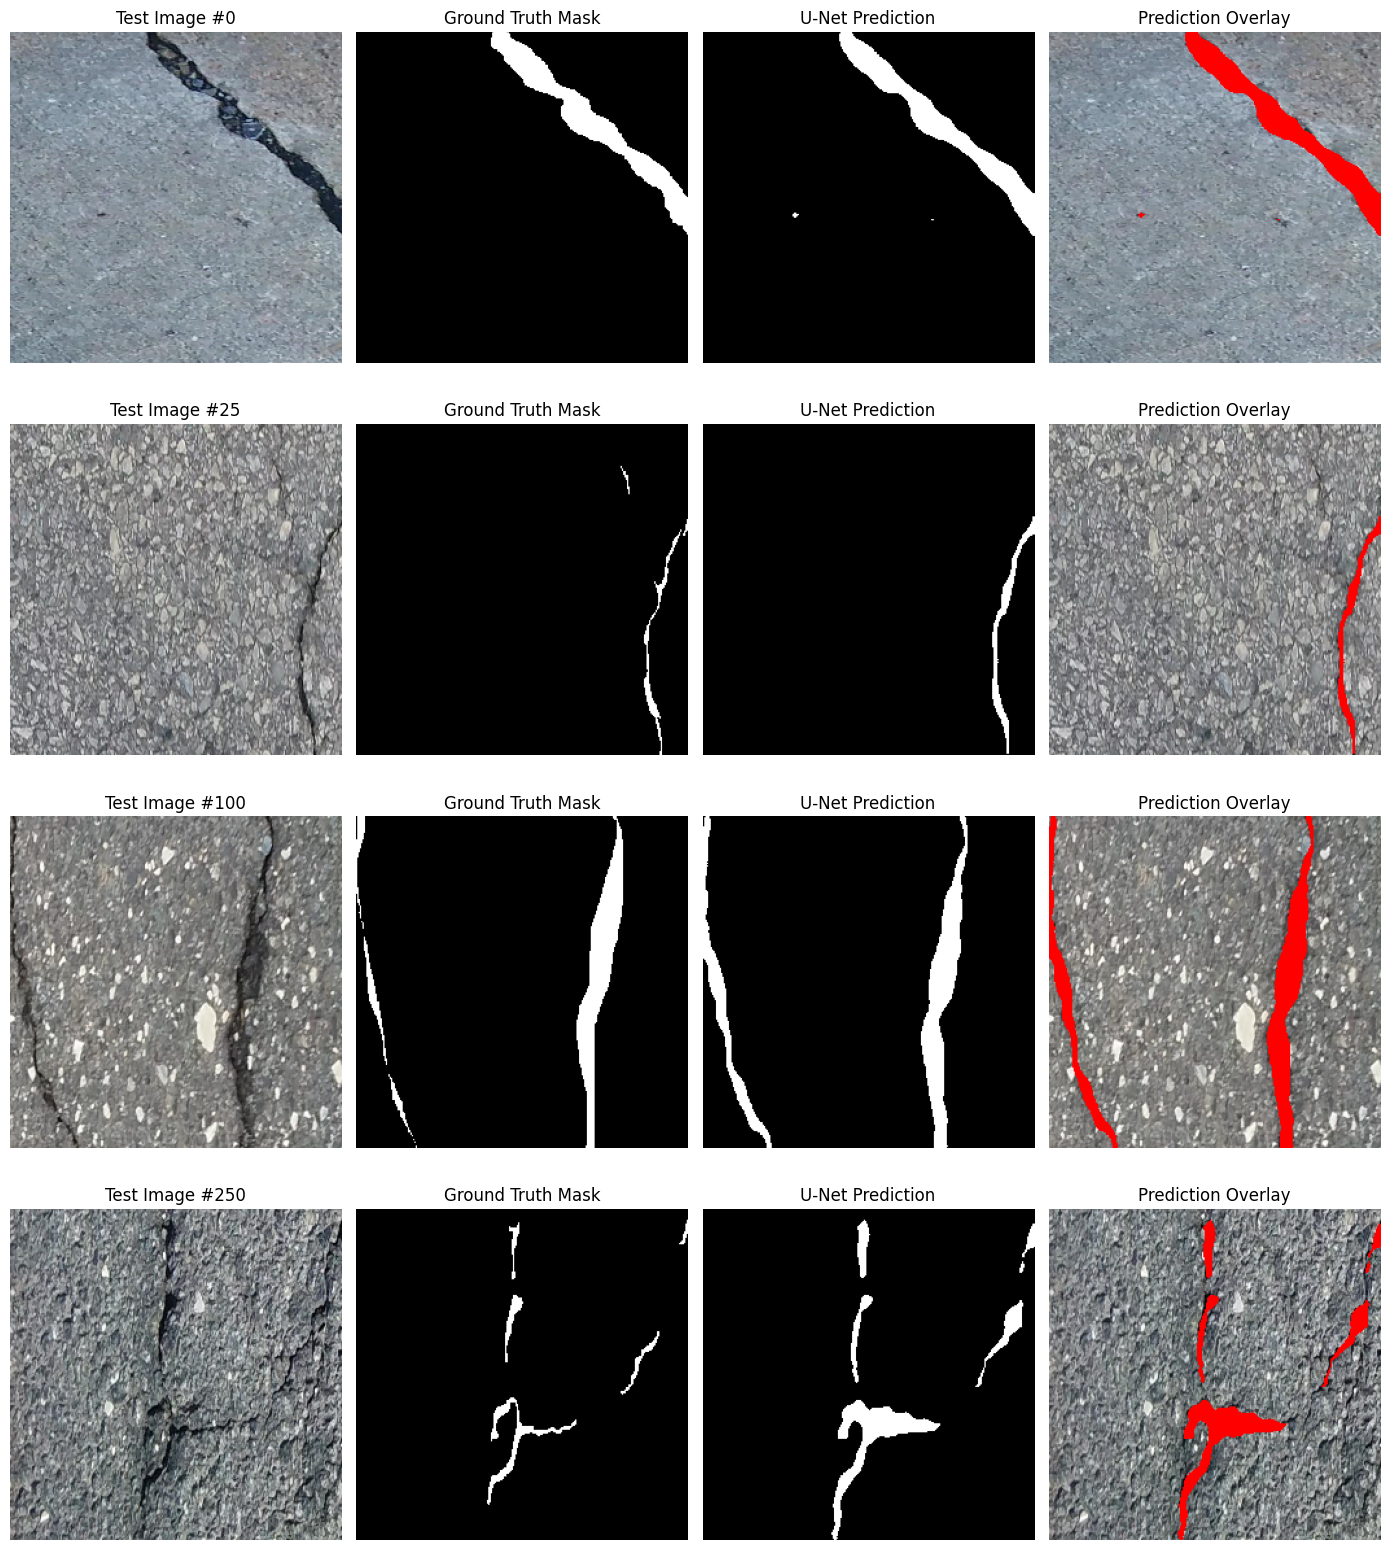

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Show 4 test examples
sample_indices = [0, 25, 100, 250]

plt.figure(figsize=(14, 4 * len(sample_indices)))

for row, idx in enumerate(sample_indices):
    image = X_test[idx]
    true_mask = y_test[idx, :, :, 0]
    pred_mask = y_pred[idx, :, :, 0]

    # Overlay predicted crack pixels in red
    overlay = image.copy()
    overlay[pred_mask == 1] = [1.0, 0.0, 0.0]

    plt.subplot(len(sample_indices), 4, row * 4 + 1)
    plt.imshow(image)
    plt.title(f"Test Image #{idx}")
    plt.axis("off")

    plt.subplot(len(sample_indices), 4, row * 4 + 2)
    plt.imshow(true_mask, cmap="gray")
    plt.title("Ground Truth Mask")
    plt.axis("off")

    plt.subplot(len(sample_indices), 4, row * 4 + 3)
    plt.imshow(pred_mask, cmap="gray")
    plt.title("U-Net Prediction")
    plt.axis("off")

    plt.subplot(len(sample_indices), 4, row * 4 + 4)
    plt.imshow(overlay)
    plt.title("Prediction Overlay")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
#crack geometry
import cv2
import numpy as np
import pandas as pd
from pathlib import Path
from tqdm.auto import tqdm

PROJECT_DIR = Path("/content/drive/MyDrive/InfraScan")
RESULTS_DIR = PROJECT_DIR / "milestone_2_results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

geometry_rows = []

for idx in tqdm(range(len(y_pred)), desc="Extracting crack geometry"):
    mask = y_pred[idx, :, :, 0].astype(np.uint8)

    # Crack area in pixels
    crack_area_px = int(np.count_nonzero(mask))

    # Skeletonize the crack mask
    skeleton = cv2.ximgproc.thinning(
        mask * 255,
        thinningType=cv2.ximgproc.THINNING_ZHANGSUEN
    )

    skeleton_length_px = int(np.count_nonzero(skeleton))

    # Approximate mean width in pixels
    mean_width_px = (
        crack_area_px / skeleton_length_px
        if skeleton_length_px > 0 else 0.0
    )

    # Connected components, excluding background
    num_labels, labels, stats, centroids = cv2.connectedComponentsWithStats(
        mask,
        connectivity=8
    )

    component_count = max(0, num_labels - 1)

    geometry_rows.append({
        "test_index": idx,
        "crack_area_px": crack_area_px,
        "skeleton_length_px": skeleton_length_px,
        "mean_width_px_approx": mean_width_px,
        "connected_components": component_count
    })

geometry_df = pd.DataFrame(geometry_rows)

geometry_path = RESULTS_DIR / "unet_crack_geometry_test.csv"
geometry_df.to_csv(geometry_path, index=False)

print("Geometry extraction completed.")
print("Rows:", len(geometry_df))
print("\nSummary:")
print(geometry_df.describe().round(3))

print("\nSaved to:", geometry_path)

Extracting crack geometry:   0%|          | 0/1124 [00:00<?, ?it/s]

Geometry extraction completed.
Rows: 1124

Summary:
       test_index  crack_area_px  skeleton_length_px  mean_width_px_approx  \
count    1124.000       1124.000            1124.000              1124.000   
mean      561.500       3511.215             321.566                10.296   
std       324.615       2517.480             174.949                 4.343   
min         0.000          0.000               0.000                 0.000   
25%       280.750       1571.000             206.000                 6.980   
50%       561.500       2938.500             307.000                 9.767   
75%       842.250       4954.250             412.250                12.880   
max      1123.000      13292.000            1367.000                32.383   

       connected_components  
count              1124.000  
mean                  3.371  
std                   2.755  
min                   0.000  
25%                   2.000  
50%                   3.000  
75%                   4.000  
max  

In [ ]:
#Model comparision
import pandas as pd
import json
from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/InfraScan")
RESULTS_DIR = PROJECT_DIR / "milestone_2_results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

comparison = pd.DataFrame([
    {
        "Model": "CNN",
        "Task": "Binary crack classification",
        "Dataset": "Concrete Crack Classification",
        "Test metric": "Accuracy",
        "Value": 0.9969,
        "Additional note": "Confusion matrix: TN=552, FP=2, FN=9, TP=2991"
    },
    {
        "Model": "YOLO11n",
        "Task": "Crack detection",
        "Dataset": "CRACK500 crop-derived pseudo-boxes",
        "Test metric": "mAP@0.50",
        "Value": 0.400,
        "Additional note": "Precision=0.597, Recall=0.380, mAP@0.50:0.95=0.221"
    },
    {
        "Model": "U-Net",
        "Task": "Pixel-level crack segmentation",
        "Dataset": "CRACK500",
        "Test metric": "IoU",
        "Value": 0.5408209063,
        "Additional note": "Dice=0.70199, Precision=0.7172, Recall=0.6874"
    }
])

comparison_path = RESULTS_DIR / "milestone_2_model_comparison.csv"
comparison.to_csv(comparison_path, index=False)

print(comparison.to_string(index=False))
print("\nSaved to:", comparison_path)

  Model                           Task                            Dataset Test metric    Value                                    Additional note
    CNN    Binary crack classification      Concrete Crack Classification    Accuracy 0.996900      Confusion matrix: TN=552, FP=2, FN=9, TP=2991
YOLO11n                Crack detection CRACK500 crop-derived pseudo-boxes    mAP@0.50 0.400000 Precision=0.597, Recall=0.380, mAP@0.50:0.95=0.221
  U-Net Pixel-level crack segmentation                           CRACK500         IoU 0.540821      Dice=0.70199, Precision=0.7172, Recall=0.6874

Saved to: /content/drive/MyDrive/InfraScan/milestone_2_results/milestone_2_model_comparison.csv


In [ ]:
from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/InfraScan")
RESULTS_DIR = PROJECT_DIR / "milestone_2_results"

print("Milestone 2 result files:")
for path in sorted(RESULTS_DIR.rglob("*")):
    if path.is_file():
        print(f"{path.relative_to(PROJECT_DIR)} | {path.stat().st_size:,} bytes")

Milestone 2 result files:
milestone_2_results/BoxF1_curve.png | 103,960 bytes
milestone_2_results/BoxPR_curve.png | 91,486 bytes
milestone_2_results/BoxP_curve.png | 105,014 bytes
milestone_2_results/BoxR_curve.png | 103,131 bytes
milestone_2_results/cnn_classification_report.json | 725 bytes
milestone_2_results/cnn_confusion_matrix.png | 90,547 bytes
milestone_2_results/confusion_matrix.png | 108,783 bytes
milestone_2_results/confusion_matrix_normalized.png | 97,900 bytes
milestone_2_results/image_quality_assessment.csv | 341,221 bytes
milestone_2_results/milestone_2_model_comparison.csv | 415 bytes
milestone_2_results/results.png | 288,110 bytes
milestone_2_results/unet_crack_geometry_test.csv | 36,560 bytes
milestone_2_results/unet_test_metrics.json | 115 bytes
milestone_2_results/unet_test_metrics_verified.json | 342 bytes
milestone_2_results/unet_test_predictions.png | 1,078,562 bytes


In [ ]:
import json
from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/InfraScan")
RESULTS_DIR = PROJECT_DIR / "milestone_2_results"

# Read verified U-Net metrics
with open(RESULTS_DIR / "unet_test_metrics_verified.json") as f:
    unet_metrics = json.load(f)

print("U-Net verified metrics:")
for key, value in unet_metrics.items():
    print(f"{key}: {value}")

# Check available YOLO evaluation artifacts
print("\nYOLO evaluation artifacts:")
for name in [
    "BoxF1_curve.png",
    "BoxPR_curve.png",
    "BoxP_curve.png",
    "BoxR_curve.png",
    "confusion_matrix.png",
    "confusion_matrix_normalized.png",
    "results.png"
]:
    path = RESULTS_DIR / name
    print(f"{name}: {'Present' if path.exists() else 'Missing'}")

U-Net verified metrics:
test_iou: 0.5408209063448854
test_dice: 0.70199061307886
test_pixel_accuracy: 0.9673754193180396
test_precision: 0.717197510975235
test_recall: 0.6874151962080592
test_TN: 68428761
test_FP: 1116110
test_FN: 1287097
test_TP: 2830496
threshold: 0.5
input_size: 256

YOLO evaluation artifacts:
BoxF1_curve.png: Present
BoxPR_curve.png: Present
BoxP_curve.png: Present
BoxR_curve.png: Present
confusion_matrix.png: Present
confusion_matrix_normalized.png: Present
results.png: Present


In [ ]:
from pathlib import Path
import json
import pandas as pd

PROJECT_DIR = Path("/content/drive/MyDrive/InfraScan")
RESULTS_DIR = PROJECT_DIR / "milestone_2_results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Load verified evaluation data
with open(RESULTS_DIR / "unet_test_metrics_verified.json") as f:
    unet = json.load(f)

cnn_path = RESULTS_DIR / "cnn_classification_report.json"
with open(cnn_path) as f:
    cnn_report = json.load(f)

comparison_path = RESULTS_DIR / "milestone_2_model_comparison.csv"
comparison = pd.read_csv(comparison_path)

geometry = pd.read_csv(
    RESULTS_DIR / "unet_crack_geometry_test.csv"
)

quality = pd.read_csv(
    RESULTS_DIR / "image_quality_assessment.csv"
)

# Summarize geometry and image-quality data
geometry_summary = geometry[
    [
        "crack_area_px",
        "skeleton_length_px",
        "mean_width_px_approx",
        "connected_components"
    ]
].describe().round(3)

quality_summary = quality.describe(include="all").round(3)

report = f"""
# InfraScan — Milestone 2 Evaluation Report

## 1. Objective

Milestone 2 evaluates crack classification, object detection, pixel-level
segmentation, image quality, and crack geometry extraction. The outputs
provide a baseline for later system integration.

## 2. Image Quality Assessment

Image quality assessment was performed on {len(quality)} images.
The generated assessment is saved as:

`image_quality_assessment.csv`

The file contains the image-level quality measurements. These are
descriptive indicators; they are not treated as strict pass/fail criteria
for crack visibility or model suitability.

## 3. CNN Crack Classification

**Dataset:** Concrete Crack Classification
**Task:** Binary classification of cracked and non-cracked images
**Test accuracy:** 0.9969

Reported confusion matrix:

- True negatives: 552
- False positives: 2
- False negatives: 9
- True positives: 2991

The CNN provides a strong classification baseline on its evaluation dataset.
Its score should not be interpreted as evidence of equivalent performance
on unseen field imagery.

## 4. YOLO Crack Detection

**Model:** YOLO11n
**Dataset:** CRACK500 crop-derived pseudo-boxes
**Test images:** 1,124
**Test instances:** 2,673

Reported test metrics:

- Precision: 0.597
- Recall: 0.380
- mAP@0.50: 0.400
- mAP@0.50:0.95: 0.221

The bounding boxes were derived from connected components in crack masks.
They are pseudo-box annotations rather than native manually annotated
bounding boxes. This limitation should be considered when interpreting
detection performance.

YOLO evaluation plots are available in this results directory:
`BoxF1_curve.png`, `BoxPR_curve.png`, `BoxP_curve.png`, `BoxR_curve.png`,
`confusion_matrix.png`, `confusion_matrix_normalized.png`, and `results.png`.

## 5. U-Net Crack Segmentation

**Dataset:** CRACK500
**Task:** Pixel-level crack segmentation
**Input size:** {unet["input_size"]} × {unet["input_size"]}
**Prediction threshold:** {unet["threshold"]}

Verified test metrics:

- IoU: {unet["test_iou"]:.4f}
- Dice: {unet["test_dice"]:.4f}
- Pixel accuracy: {unet["test_pixel_accuracy"]:.4f}
- Precision: {unet["test_precision"]:.4f}
- Recall: {unet["test_recall"]:.4f}

Pixel-level confusion counts:

- TN: {unet["test_TN"]:,}
- FP: {unet["test_FP"]:,}
- FN: {unet["test_FN"]:,}
- TP: {unet["test_TP"]:,}

Pixel accuracy is influenced by the large number of background pixels.
IoU and Dice are therefore included as more informative overlap metrics
for crack segmentation.

Qualitative predictions were inspected against ground-truth masks.
The examples showed useful alignment with major crack structures, along
with some false positives, boundary differences, and variations in
predicted crack thickness.

## 6. Crack Geometry Extraction

Geometry was extracted from the predicted binary masks for
{len(geometry)} test images.

Summary statistics:

{geometry_summary.to_string()}

Measurements are reported in image-space pixels:

- Crack area: number of predicted crack pixels
- Skeleton length: number of pixels in the thinned skeleton
- Approximate mean width: crack area divided by skeleton length
- Connected components: number of detected foreground components

These values are image-space estimates. No conversion to millimeters or
centimeters is made because no physical scale calibration is available.
The area-to-skeleton ratio is an approximate width proxy, not a calibrated
width measurement. Fragmentation and false-positive components can affect
these geometry values.

The detailed per-image results are saved in:
`unet_crack_geometry_test.csv`

## 7. Model Comparison

{comparison.to_string(index=False)}

The models perform different tasks and were evaluated using different
datasets and metrics. Their numerical scores should not be compared as
though they were a common ranking:

- CNN predicts an image-level crack class.
- YOLO predicts bounding boxes using crop-derived pseudo-labels.
- U-Net predicts crack pixels using segmentation masks.

The CNN accuracy, YOLO mAP, and U-Net IoU measure different properties.
They provide task-specific baselines rather than a single overall winner.

## 8. Limitations

1. The CNN evaluation uses a separate classification dataset.
2. YOLO training and evaluation use pseudo-boxes derived from mask
   connected components.
3. Crack geometry is measured in pixels, without physical calibration.
4. Segmentation results can be affected by mask boundary differences,
   false positives, and disconnected predictions.
5. The reported metrics do not establish generalization to all real-world
   infrastructure conditions.

## 9. Conclusion

Milestone 2 establishes baseline results for binary crack classification,
crack detection, and crack segmentation. Image quality assessment,
segmentation evaluation, and image-space geometry extraction have also
been completed for the current datasets.

The CNN provides an image-level classification baseline, YOLO11n provides
a detection baseline, and U-Net provides pixel-level segmentation and
geometry inputs. The results can inform subsequent integration and
validation work, subject to the dataset and annotation limitations stated
above.
"""

report_path = RESULTS_DIR / "milestone_2_evaluation_report.md"
report_path.write_text(report.strip(), encoding="utf-8")

print("Report created:", report_path)
print("Report size:", f"{report_path.stat().st_size:,} bytes")

Report created: /content/drive/MyDrive/InfraScan/milestone_2_results/milestone_2_evaluation_report.md
Report size: 6,257 bytes
